<div align="center">

# Proyecto Integrador de Ciencia de Datos
## Fase 2 (actividades 3 y 4) · Preparación de los datos, partición y modelo base

### ¿Cuál es la energía renovable con mejor desempeño integral?
#### Limpieza e imputación, ingeniería de variables, partición de datos y modelo base con la *Global Power Plant Database* (WRI)

**Carolina Rodríguez Chacón** · carodriguez03@unisalle.edu.co<br>
Maestría en Inteligencia Artificial · Facultad de Ingeniería · **Universidad de La Salle**<br>
**Curso:** 2026-2_Ciencia de Datos_G2 · **Docente:** Fabián Camilo Castro Riveros<br>
**Actividades del aula:** Fase 2, actividades 3 y 4 – Limpieza de datos e ingeniería de variables; partición de datos y modelo base (Entregable 2, 25 %)<br>
**Cierre en el aula:** Actividad 3, 8 de noviembre; Actividad 4, 15 de noviembre de 2026 · **Fecha de elaboración:** noviembre de 2026

</div>

---

### Qué es este cuaderno

Este cuaderno acompaña al informe de la Fase 2 y **reproduce todas sus tablas y figuras** con el mismo número. Contiene solo el trabajo de la Fase 2. El planteamiento del problema, el diccionario de datos y el análisis exploratorio están en el Entregable 1 (Fase 1); aquí la sección 0 solo reconstruye, sin repetir ese análisis, el punto de partida que necesita la Fase 2: descarga los datos y recalcula los indicadores de la Fase 1 con el mismo código y la misma semilla.

Es reproducible de principio a fin: si los datos no están en `data/raw/`, los descarga del repositorio oficial del WRI (funciona igual en Google Colab y en Jupyter local), verifica su huella SHA-256 y usa `SEMILLA = 42`. Las versiones de las librerías están en `requirements.txt`.

| Informe | Contenido | Sección del cuaderno |
|---|---|---|
| — | Punto de partida: datos e indicadores de la Fase 1 | 0 |
| Sección II-A | Principio contra la fuga de datos y orden de los pasos | 1 |
| Sección II-B y Tabla I | Limpieza basada en reglas, selección de columnas y sitios compartidos (Actividad 3) | 2 |
| Sección II-C | Variables derivadas del dominio (Actividad 3) | 3 |
| Sección II-D y Tabla II | Partición 70 / 15 / 15 estratificada y agrupada (Actividad 4) | 4 |
| Secciones II-E a II-G, Tablas III–IV y Fig. 1 | Mecanismo de faltantes, imputación, winsorización, codificación y escalamiento (Actividad 3) | 5 |
| Sección II-H | Objetivo de clasificación y desbalance (Actividad 4) | 6 |
| Sección III, Tablas V–VII y Figs. 2–4 | Modelos base, diagnóstico y métrica inicial (Actividad 4) | 7 |
| — | Auditoría de fuga, artefactos y hallazgos | 8–10 |
| Secciones V–VI | Limitaciones y referencias | 11–12 |

# 0. Punto de partida: datos e indicadores de la Fase 1

La Fase 2 parte exactamente del universo que dejó la Fase 1: las **24 794 plantas renovables** de la GPPD v1.3.0 con sus indicadores (tecnología en español, factor de planta válido por año y promedio, coeficiente de variación, distancia al ecuador, nivel de desempeño, marca de bombeo, etc.). Las celdas de esta sección son las mismas del cuaderno de la Fase 1 (librerías y estilo, descarga y verificación del archivo, cálculo de los indicadores y funciones auxiliares), sin el análisis exploratorio, que ya se entregó.

Recordatorio de las decisiones de la Fase 1 que se usan aquí:
- El **factor de planta** (FP) de un año es válido solo si $0 < FP \le 1$, si el año es posterior a la puesta en marcha y si la planta no es de bombeo; el objetivo de regresión es su promedio 2013–2019 (`factor_planta_prom`).
- La generación reportada falta en el 75.7 % de las plantas, bajo un mecanismo **MAR** que depende del país (§5.2 de la Fase 1): por eso el objetivo no se imputa.
- La paradoja de Simpson encontrada en la Fase 1 (§7.3) exige modelar **interacciones tecnología × variable**.
- Metas SMART del objetivo OE2: **R² ≥ 0.55** en regresión y **F1-macro ≥ 0.70** en clasificación.

In [1]:
# ---------------------------------------------------------------------------
# Librerías y configuración general
# ---------------------------------------------------------------------------
import hashlib
import logging
import platform
import urllib.request
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import scipy
from scipy import stats
import statsmodels
import statsmodels.formula.api as smf
from statsmodels.nonparametric.smoothers_lowess import lowess
import sklearn
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, f1_score, mean_absolute_error,
                             mean_squared_error, r2_score, silhouette_score)
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

SEMILLA = 42                      # semilla única para que todo sea reproducible
rng = np.random.default_rng(SEMILLA)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# --- Estilo de gráficos: superficie clara, retícula fina y marcas delgadas ---
TINTA, TINTA2, TENUE = "#0b0b0b", "#52514e", "#898781"
GRIS, RETICULA, SUPERFICIE = "#c3c2b7", "#e1e0d9", "#fcfcfb"
AZUL = "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "xtick.color": TENUE, "ytick.color": TENUE, "xtick.labelcolor": TINTA2, "ytick.labelcolor": TINTA2,
    "text.color": TINTA, "axes.grid": True, "grid.color": RETICULA, "grid.linewidth": 0.6,
    "grid.linestyle": "-", "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.labelsize": 10, "legend.frameon": False,
    "legend.fontsize": 9, "figure.dpi": 100, "lines.linewidth": 2, "figure.titlesize": 13,
    "figure.titleweight": "bold",
})

# --- Tecnologías: etiqueta en español y color fijo (validado para daltonismo) ---
MAPA_TEC = {"Solar": "Solar", "Wind": "Eólica", "Hydro": "Hidroeléctrica",
            "Geothermal": "Geotérmica", "Biomass": "Biomasa", "Wave and Tidal": "Mareomotriz/undimotriz"}
TEC_ORDEN = list(MAPA_TEC.values())
TEC_COLOR = {"Solar": "#eda100", "Eólica": "#1baf7a", "Hidroeléctrica": "#2a78d6",
             "Geotérmica": "#e34948", "Biomasa": "#008300", "Mareomotriz/undimotriz": "#6250d6"}
TEC_CON_GENERACION = TEC_ORDEN[:5]        # la mareomotriz no tiene generación reportada

# Rampas: secuencial (una sola tonalidad) y divergente (azul ↔ rojo con gris neutro al centro)
CMAP_SEQ = LinearSegmentedColormap.from_list("seq_azul", ["#f4f8fd", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
CMAP_DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a3a2", "#b8302f"])
ORDINAL_3 = ["#86b6ef", "#2a78d6", "#104281"]

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scipy {scipy.__version__} | statsmodels {statsmodels.__version__} | scikit-learn {sklearn.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.13.3 | pandas 2.2.3 | numpy 2.2.5 | scipy 1.15.2 | statsmodels 0.15.0 | scikit-learn 1.7.0 | matplotlib 3.10.1 | seaborn 0.13.2


### 0.1 Descarga y verificación de los datos

In [2]:
URL_ZIP = "https://wri-dataportal-prod.s3.amazonaws.com/manual/global_power_plant_database_v_1_3.zip"
RAIZ = Path("..") if Path("../data").exists() else Path(".")      # carpeta notebooks/ o Colab
DIR_RAW = RAIZ / "data" / "raw" / "gppd_v1_3"
RUTA_CSV = DIR_RAW / "global_power_plant_database.csv"

if not RUTA_CSV.exists():
    DIR_RAW.mkdir(parents=True, exist_ok=True)
    ruta_zip = DIR_RAW.parent / "gppd_v1_3.zip"
    print("Descargando dataset desde el repositorio del WRI ...")
    urllib.request.urlretrieve(URL_ZIP, ruta_zip)
    with zipfile.ZipFile(ruta_zip) as z:
        z.extract(RUTA_CSV.name, DIR_RAW)          # solo el CSV; la documentación queda dentro del ZIP

df_raw = pd.read_csv(RUTA_CSV, low_memory=False, encoding="utf-8")
sha256 = hashlib.sha256(RUTA_CSV.read_bytes()).hexdigest()

print(f"Archivo: {RUTA_CSV.name}  ({RUTA_CSV.stat().st_size / 1e6:.2f} MB)")
print(f"SHA-256: {sha256}")
print(f"Dimensiones del dataset completo: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")
print(f"Países: {df_raw['country'].nunique()} | Fuentes primarias: {df_raw['primary_fuel'].nunique()}")
print(f"Columnas numéricas: {df_raw.select_dtypes('number').shape[1]} | Columnas de texto: {df_raw.select_dtypes('object').shape[1]}")

Archivo: global_power_plant_database.csv  (11.97 MB)
SHA-256: 4b1f93e0fd93664f18684d9b05d0a52ed9658c6a8cf0d21ff2520791379ba7fc
Dimensiones del dataset completo: 34,936 filas × 36 columnas
Países: 167 | Fuentes primarias: 15
Columnas numéricas: 17 | Columnas de texto: 19


### 0.2 Universo renovable e indicadores de la Fase 1

In [3]:
RENOVABLES = list(MAPA_TEC)
ANIOS = list(range(2013, 2020))
COLS_GEN = [f"generation_gwh_{a}" for a in ANIOS]
COLS_ORIG = list(df_raw.columns)


def construir_indicadores(d):
    # Añade los indicadores exploratorios sin eliminar filas
    d = d.copy()
    d["tecnologia"] = pd.Categorical(d["primary_fuel"].map(MAPA_TEC), categories=TEC_ORDEN)
    anio_op = np.floor(d["commissioning_year"])
    d["anio_operacion"] = anio_op

    # Bombeo: por nombre o por cualquier año con generación neta negativa
    d["posible_bombeo"] = (d["name"].str.contains("pump", case=False, na=False)
                           | (d[COLS_GEN] < 0).any(axis=1))

    # Factor de planta bruto por año y máscara de validez
    fp = pd.DataFrame({a: d[f"generation_gwh_{a}"] / (d["capacity_mw"] * 8.76) for a in ANIOS}, index=d.index)
    anio_parcial = pd.DataFrame({a: anio_op.notna() & (anio_op >= a) for a in ANIOS}, index=d.index)
    valido = fp.gt(0) & fp.le(1) & ~anio_parcial
    valido = valido.apply(lambda col: col & ~d["posible_bombeo"])
    fp_valido = fp.where(valido)

    for a in ANIOS:
        d[f"factor_planta_{a}"] = fp_valido[a]
    d["n_anios_generacion"] = fp_valido.notna().sum(axis=1)
    d["factor_planta_prom"] = fp_valido.mean(axis=1)
    d["generacion_prom_gwh"] = d[COLS_GEN].where(valido.values).mean(axis=1)
    d["cv_generacion"] = (fp_valido.std(axis=1, ddof=1) / fp_valido.mean(axis=1)).where(d["n_anios_generacion"] >= 3)
    d["tiene_generacion"] = d["n_anios_generacion"] > 0

    # Variables geográficas y de escala
    d["latitud_abs"] = d["latitude"].abs()
    d["hemisferio"] = np.where(d["latitude"] >= 0, "Norte", "Sur")
    d["zona_climatica"] = pd.cut(d["latitud_abs"], [0, 23.5, 35, 55, 90.01], right=False,
                                 labels=["Tropical", "Subtropical", "Templada", "Fría"])
    d["rango_capacidad"] = pd.cut(d["capacity_mw"], [1, 5, 20, 100, 500, np.inf], right=False,
                                  labels=["1–5 MW", "5–20 MW", "20–100 MW", "100–500 MW", "≥500 MW"])
    d["periodo_operacion"] = pd.cut(anio_op, [-np.inf, 1970, 1990, 2000, 2010, np.inf], right=False,
                                    labels=["Antes de 1970", "1970–1989", "1990–1999", "2000–2009", "2010–2020"])
    d["nivel_desempeno"] = pd.qcut(d["factor_planta_prom"], 3, labels=["Bajo", "Medio", "Alto"])
    return d


df = construir_indicadores(df_raw[df_raw["primary_fuel"].isin(RENOVABLES)].reset_index(drop=True))
df_fp = df[df["tiene_generacion"]].copy()            # subconjunto con rendimiento medible

print(f"Plantas renovables (universo de análisis): {len(df):,} en {df['country'].nunique()} países")
print(f"Plantas con factor de planta válido:        {len(df_fp):,} ({len(df_fp) / len(df):.1%})")
print(f"Plantas marcadas como posible bombeo:        {df['posible_bombeo'].sum():,}")
print("Cortes de los terciles del FP (nivel_desempeno):",
      np.round(df_fp["factor_planta_prom"].quantile([1/3, 2/3]).values, 3))

resumen_universo = df.groupby("tecnologia", observed=True).agg(
    plantas=("gppd_idnr", "size"), paises=("country", "nunique"),
    capacidad_gw=("capacity_mw", lambda s: s.sum() / 1000),
    con_generacion=("tiene_generacion", "sum"))
resumen_universo["% con generación"] = resumen_universo["con_generacion"] / resumen_universo["plantas"] * 100
resumen_universo

Plantas renovables (universo de análisis): 24,794 en 150 países
Plantas con factor de planta válido:        6,031 (24.3%)
Plantas marcadas como posible bombeo:        71
Cortes de los terciles del FP (nivel_desempeno): [0.205 0.324]


,plantas,paises,capacidad_gw,con_generacion,% con generación
tecnologia,,,,,
Solar,10665,92,188.312,2702,25.335
Eólica,5344,58,263.054,1126,21.070
Hidroeléctrica,7156,128,"1,053.160",1972,27.557
Geotérmica,189,22,12.688,66,34.921
Biomasa,1430,38,34.281,165,11.538
Mareomotriz/undimotriz,10,4,0.552,0,0.000


### 0.3 Funciones auxiliares

In [4]:
# Funciones auxiliares de la Fase 1 que reutiliza la Fase 2 (prueba χ², resumen cuantitativo y formato de figuras)
def prueba_chi2(d, fila, col):
    # Prueba χ² de independencia con V de Cramér y verificación de frecuencias esperadas
    tabla = pd.crosstab(d[fila], d[col])
    tabla = tabla.loc[tabla.sum(axis=1) > 0, tabla.sum(axis=0) > 0]
    chi2, p, gl, esperadas = stats.chi2_contingency(tabla)
    n = tabla.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
    return {"variables": f"{fila} × {col}", "n": n, "χ²": chi2, "gl": gl, "p-valor": p,
            "V de Cramér": v, "% celdas esperada<5": (esperadas < 5).mean() * 100}


def resumen_cuantitativo(d, columnas):
    filas = {}
    for c in columnas:
        s = d[c].dropna().astype(float)
        moda = s.round(2).mode()
        filas[c] = {
            "n": len(s), "% faltante": d[c].isna().mean() * 100,
            "media": s.mean(), "mediana": s.median(), "moda": moda.iloc[0] if len(moda) else np.nan,
            "desv. estándar": s.std(), "varianza": s.var(), "CV (%)": s.std() / s.mean() * 100 if s.mean() else np.nan,
            "mínimo": s.min(), "Q1": s.quantile(0.25), "Q3": s.quantile(0.75), "IQR": s.quantile(0.75) - s.quantile(0.25),
            "máximo": s.max(), "rango": s.max() - s.min(),
            "asimetría": stats.skew(s, bias=False), "curtosis (exceso)": stats.kurtosis(s, fisher=True, bias=False),
        }
    return pd.DataFrame(filas).T


# Formato de las figuras del informe (ancho de una columna IEEE: 3.45 pulgadas)
ESTILO_INFORME = {
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"], "font.size": 8,
    "axes.labelsize": 8, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "xtick.labelcolor": TINTA2, "ytick.labelcolor": TINTA2, "axes.titlecolor": TINTA, "text.color": TINTA,
    "axes.titlesize": 8, "axes.titleweight": "normal", "axes.grid": True, "grid.color": RETICULA,
    "grid.linewidth": 0.5, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "lines.linewidth": 1.5, "figure.dpi": 170,
}
ANCHO_COLUMNA = 3.45
DIR_FIG = RAIZ / "reports" / "articulo_ieee" / "figuras"


def guardar_figura(fig, nombre):
    # En la copia local del proyecto la figura se guarda para el informe; en Colab solo se muestra
    if DIR_FIG.exists():
        fig.savefig(DIR_FIG / nombre, dpi=300)


def etiqueta_panel(ax, texto):
    ax.text(-0.02, 1.04, texto, transform=ax.transAxes, fontsize=8.5, fontweight="bold", ha="right", va="bottom")

# 1. Hoja de ruta de la Fase 2

La Fase 1 (Entregable 1) dejó tres insumos: el universo de 24 794 plantas con sus indicadores, el diagnóstico de calidad (§5 de la Fase 1) y una prueba de concepto (§9 de la Fase 1). La Fase 2 convierte esa exploración en un **conjunto de modelado limpio, una partición sin fuga de datos y dos modelos base** que fijan el umbral mínimo que deberán superar los modelos de la Fase 3.

**Principio rector.** Todo paso que *aprende algo de los datos* (un promedio para imputar, un percentil para recortar, la media de un escalador, la codificación de un país, los cortes de los terciles) se ajusta **solo con el conjunto de entrenamiento**. Por eso el orden de las secciones no es el de la lista de la guía, sino el que impide la fuga de datos:

| Sección | Qué se hace | ¿Aprende de los datos? | Actividad del aula |
|---|---|---|---|
| 2 | Limpieza con **reglas** fijadas de antemano (física y documentación del WRI) y selección de columnas | No: las reglas no dependen de la muestra | Actividad 3 |
| 3 | Variables derivadas **deterministas** del dominio (fórmulas sin parámetros) | No | Actividad 3 |
| 4 | **Partición** 70 / 15 / 15 estratificada y agrupada por sitio | — | Actividad 4 |
| 5 | Mecanismo de los faltantes, **imputación**, recorte de atípicos, **codificación** y **escalamiento**, todo dentro de un *pipeline* | **Sí → solo entrenamiento** | Actividad 3 |
| 6 | Cortes de las clases y **desbalance** | **Sí → solo entrenamiento** | Actividad 4 |
| 7 | **Modelos base** de regresión y clasificación, diagnóstico y métrica inicial | **Sí → solo entrenamiento**; el conjunto de prueba se usa una sola vez, al final | Actividad 4 |
| 8–10 | Auditoría de fuga, artefactos guardados y hallazgos | — | Actividades 3 y 4 |

**Correspondencia con la lista de chequeo de la Fase 2 (guía §5)**

| Ítem de la guía | Dónde se cumple |
|---|---|
| Tratamiento de faltantes con análisis previo del mecanismo (MCAR, MAR, MNAR) y justificación de la técnica | §5.1 (mecanismo) y §5.2 (experimento que compara eliminación, media, mediana, KNN e imputación iterativa) |
| Tratamiento razonado de atípicos: remoción, transformación logarítmica o recorte por percentiles | §2.2 (remoción por imposibilidad física), §3 (log10 de la capacidad) y §5.3 (*winsorización* ajustada en entrenamiento) |
| Al menos 2 variables derivadas respaldadas en el dominio | §3 (cuatro variables) y §5.4 (interacciones tecnología × variable) |
| Codificación de categóricas sin fuga (*One-Hot*, *Target*, *Ordinal*) | §5.5 |
| Escalamiento ajustado solo con entrenamiento | §5.5 y verificación en §8 |
| Partición entrenamiento (70–80 %), validación y prueba (20–30 %), estratificada en clasificación | §4 |
| Desbalance de clases (SMOTE, ADASYN o `class_weight`) si aplica | §6 |
| Modelo base (regresión lineal / logística / *Dummy*) con su métrica inicial | §7 |

In [5]:
# ---------------------------------------------------------------------------
# Fase 2 · librerías adicionales, carpetas de salida y constantes
# ---------------------------------------------------------------------------
import json
import joblib
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (habilita IterativeImputer)
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.linear_model import BayesianRidge, LogisticRegression
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, StratifiedKFold, learning_curve
from sklearn.neighbors import BallTree
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

DIR_FIG2 = RAIZ / "reports" / "figuras_fase2"
DIR_MOD = RAIZ / "models"
DIR_PROC = RAIZ / "data" / "processed"
for carpeta in (DIR_FIG2, DIR_MOD, DIR_PROC):
    carpeta.mkdir(parents=True, exist_ok=True)


def guardar_fig2(fig, nombre):
    # Las figuras de la Fase 2 se guardan siempre (también en Colab) para el informe final
    fig.savefig(DIR_FIG2 / nombre, dpi=200, bbox_inches="tight")


TEC_MODELO = TEC_CON_GENERACION          # Solar (referencia), Eólica, Hidroeléctrica, Geotérmica, Biomasa
ANIO_REFERENCIA = 2019                   # último año de la ventana de generación 2013–2019
ORDEN_CONJ = ["entrenamiento", "validación", "prueba"]
NIVELES = ["Bajo", "Medio", "Alto"]
print(f"Fase 2 lista | joblib {joblib.__version__} | figuras en {DIR_FIG2} | modelos en {DIR_MOD}")

Fase 2 lista | joblib 1.5.1 | figuras en ..\reports\figuras_fase2 | modelos en ..\models


# 2. Limpieza basada en reglas (Actividad 3)

Las reglas de esta sección se fijan con conocimiento del dominio y con la documentación del WRI, **no** con estadísticos de la muestra. Por eso se pueden aplicar a todo el conjunto antes de la partición sin introducir fuga de datos: una planta nueva se filtraría exactamente igual.

## 2.1 Del universo al conjunto de modelado

La variable objetivo, el factor de planta (FP), **no se imputa**. La §5.2 de la Fase 1 mostró que su ausencia es MAR (depende del país: EE. UU. reporta el 87 % de sus plantas y el resto del mundo el 4 %), con un posible componente MNAR. Imputar la respuesta inventaría la cantidad que se quiere predecir y reproduciría el sesgo del mecanismo de falta. Se modela solo con las plantas que la reportan y el sesgo hacia EE. UU. se mide (§7.5) y se declara como limitación.

In [6]:
embudo = []


def registrar(paso, datos, criterio):
    # Lleva la cuenta de cuántas plantas sobreviven a cada regla
    anterior = embudo[-1]["plantas"] if embudo else len(datos)
    embudo.append({"paso": paso, "criterio": criterio, "plantas": len(datos),
                   "retiradas en el paso": anterior - len(datos),
                   "% en EE. UU.": (datos["country"] == "USA").mean() * 100})


registrar("0. Universo renovable (Fase 1)", df, "Seis familias renovables de la GPPD")
d1 = df[df["tecnologia"] != "Mareomotriz/undimotriz"]
registrar("1. Sin mareomotriz", d1, "Sus 10 plantas no tienen generación reportada (§10.3 de la Fase 1)")
d2 = d1[d1["tiene_generacion"]]
registrar("2. Con factor de planta válido", d2,
          "Generación reportada válida: sin bombeo, sin años parciales y 0 < FP ≤ 1 (§4.2 de la Fase 1)")
print(f"Paso 2: se conservan {len(d2):,} plantas; la variable objetivo no se imputa en las {len(d1) - len(d2):,} restantes")

Paso 2: se conservan 6,031 plantas; la variable objetivo no se imputa en las 18,753 restantes


## 2.2 Atípicos físicamente imposibles: remoción

La §5.5 de la Fase 1 encontró factores de planta extremos *dentro* de cada tecnología. La guía admite tres tratamientos (remoción, transformación logarítmica y recorte por percentiles) y cada uno sirve para un caso distinto:

- **Remoción** cuando el valor es **imposible** y, por tanto, un error de registro. No se decide con un percentil de la muestra, sino con un límite físico:
  - **Solar ≤ 0.40.** Un panel fotovoltaico no supera el ~35 % de factor de planta ni con seguimiento en dos ejes en el mejor desierto (Duffie y Beckman, 2013; IRENA, 2024). Un valor de 0.70 corresponde a una planta híbrida o a una capacidad mal reportada.
  - **Eólica ≤ 0.65.** Los mejores parques terrestres y marinos rondan 0.50–0.55 (IRENA, 2024). *Horns Rev A* con 0.97 es generación de más de un parque asignada a uno solo (§5.4 de la Fase 1).
  - **FP ≥ 0.01 en todas.** Menos de 88 horas equivalentes a plena carga al año describe una planta prácticamente detenida (fuera de servicio, en desmantelamiento o con la capacidad mal registrada), no el desempeño de una tecnología.
  - El límite superior FP ≤ 1 de las demás tecnologías ya se aplicó en la §4.2 de la Fase 1.
- **Transformación logarítmica** cuando el valor extremo es **real** pero la escala lo vuelve influyente: la capacidad (§3).
- **Recorte por percentiles** (*winsorización*) cuando el valor es real pero se quiere limitar su palanca en un modelo lineal. Como el percentil se estima con los datos, se ajusta solo con entrenamiento (§5.3).

In [7]:
LIMITE_SUPERIOR_FP = {"Solar": 0.40, "Eólica": 0.65}      # demás tecnologías: 1.0 (ya aplicado en §4.2 de la Fase 1)
LIMITE_INFERIOR_FP = 0.01

limite_sup = d2["tecnologia"].astype(str).map(LIMITE_SUPERIOR_FP).fillna(1.0)
motivo = np.select([d2["factor_planta_prom"] > limite_sup, d2["factor_planta_prom"] < LIMITE_INFERIOR_FP],
                   ["FP por encima del máximo físico", "FP < 0.01 (planta casi sin operar)"], default="")
retiradas = d2.assign(motivo=motivo)[motivo != ""]
d3 = d2[motivo == ""].copy()
registrar("3. Factor de planta plausible", d3, "Solar ≤ 0.40, eólica ≤ 0.65 y FP ≥ 0.01")

display(Markdown(f"**Plantas retiradas por imposibilidad física: {len(retiradas)} "
                 f"({len(retiradas) / len(d2):.2%} de las plantas con FP)**"))
display(retiradas.groupby(["motivo", "tecnologia"], observed=True).size().rename("plantas").to_frame())
(retiradas.sort_values("factor_planta_prom", ascending=False)
 [["name", "country", "tecnologia", "capacity_mw", "factor_planta_prom", "n_anios_generacion", "motivo"]]
 .head(10).style.format({"capacity_mw": "{:,.1f}", "factor_planta_prom": "{:.3f}"}).hide(axis="index"))

**Plantas retiradas por imposibilidad física: 20 (0.33% de las plantas con FP)**

plantas
motivo                             tecnologia             
FP < 0.01 (planta casi sin operar) Solar                 5
                                   Eólica                2
                                   Hidroeléctrica        7
FP por encima del máximo físico    Solar                 4
                                   Eólica                2

name,country,tecnologia,capacity_mw,factor_planta_prom,n_anios_generacion,motivo
Horns Rev A,DNK,Eólica,160.0,0.973,1,FP por encima del máximo físico
Kilroy Solar,USA,Solar,1.1,0.697,1,FP por encima del máximo físico
Snowtown South,AUS,Eólica,126.0,0.687,5,FP por encima del máximo físico
DG Webster LLC CSG,USA,Solar,1.3,0.619,1,FP por encima del máximo físico
Phoenix Airport Rental Car Center,USA,Solar,1.6,0.450,6,FP por encima del máximo físico
Bullock Road Solar 1,USA,Solar,1.9,0.449,1,FP por encima del máximo físico
Wivenhoe Hydroelectric,AUS,Hidroeléctrica,500.0,0.009,6,FP < 0.01 (planta casi sin operar)
Crosscut,USA,Hidroeléctrica,3.0,0.008,1,FP < 0.01 (planta casi sin operar)
Parkes Solar Farm,AUS,Solar,66.0,0.008,1,FP < 0.01 (planta casi sin operar)
Sierra SunTower Solar Gen Station,USA,Solar,7.5,0.001,1,FP < 0.01 (planta casi sin operar)


## 2.3 Selección de columnas: el criterio anti-fuga

La pregunta que decide si una columna puede ser predictora es: **¿se conocería antes de que la planta opere?** El modelo debe servir para evaluar una planta *antes* de construirla (§2.2 de la Fase 1). Cualquier columna calculada con la generación observada le daría al modelo la respuesta.

In [8]:
COLS_EST = [c for c in COLS_ORIG if c.startswith("estimated_generation")]
COLS_FP_ANUAL = [f"factor_planta_{a}" for a in ANIOS]
SELECCION = [
    ("Clave (se conserva, no predice)", ["gppd_idnr"], "Identificador único de la planta"),
    ("Descartada: texto libre o identificador externo", ["name", "url", "wepp_id"], "No generaliza a plantas nuevas"),
    ("Descartada: duplica otra columna", ["country_long", "primary_fuel", "commissioning_year"],
     "Equivalen a country, tecnologia y anio_operacion"),
    ("Descartada: metadatos del reporte", ["source", "geolocation_source", "year_of_capacity_data", "generation_data_source"],
     "Describen quién reporta, no la planta; generation_data_source además delata quién tiene generación"),
    ("Descartada: faltantes críticos", ["other_fuel1", "other_fuel2", "other_fuel3", "owner"],
     "99 % y 48 % de faltantes en el universo (§5.1 de la Fase 1); sin relación con las preguntas"),
    ("Descartada: FUGA (insumos del objetivo)", COLS_GEN + COLS_FP_ANUAL +
     ["generacion_prom_gwh", "n_anios_generacion", "cv_generacion", "tiene_generacion", "posible_bombeo"],
     "El factor de planta se calcula con ellas"),
    ("Descartada: CIRCULARIDAD (generación estimada)", COLS_EST, "Salen de modelos del WRI que usan factores de planta (§2.5 de la Fase 1)"),
    ("Descriptiva: discretiza una variable continua", ["hemisferio", "zona_climatica", "rango_capacidad", "periodo_operacion"],
     "Redundante con la variable continua; se usa solo para describir"),
    ("Objetivo", ["factor_planta_prom", "nivel_desempeno"], "Regresión (PS1) y clasificación (PS2)"),
    ("Predictora", ["tecnologia", "country", "capacity_mw", "latitude", "longitude", "latitud_abs", "anio_operacion"],
     "Se conocen antes de que la planta opere; de ellas salen las variables derivadas de §3"),
]
tabla_sel = pd.DataFrame([{"decisión": dec, "n.º columnas": len(cols), "columnas": ", ".join(cols[:6]) + (" …" if len(cols) > 6 else ""),
                           "motivo": mot} for dec, cols, mot in SELECCION])
clasificadas = [c for _, cols, _ in SELECCION for c in cols]
assert sorted(clasificadas) == sorted(d3.columns), "Cada columna debe tener exactamente una decisión"
print(f"{len(d3.columns)} columnas clasificadas: {sum(len(c) for d, c, _ in SELECCION if d == 'Predictora')} predictoras, "
      f"{sum(len(c) for d, c, _ in SELECCION if 'FUGA' in d or 'CIRCULARIDAD' in d)} descartadas por fuga o circularidad")
tabla_sel.style.hide(axis="index").set_properties(**{"text-align": "left"})

57 columnas clasificadas: 7 predictoras, 29 descartadas por fuga o circularidad


decisión,n.º columnas,columnas,motivo
"Clave (se conserva, no predice)",1,gppd_idnr,Identificador único de la planta
Descartada: texto libre o identificador externo,3,"name, url, wepp_id",No generaliza a plantas nuevas
Descartada: duplica otra columna,3,"country_long, primary_fuel, commissioning_year","Equivalen a country, tecnologia y anio_operacion"
Descartada: metadatos del reporte,4,"source, geolocation_source, year_of_capacity_data, generation_data_source","Describen quién reporta, no la planta; generation_data_source además delata quién tiene generación"
Descartada: faltantes críticos,4,"other_fuel1, other_fuel2, other_fuel3, owner",99 % y 48 % de faltantes en el universo (§5.1 de la Fase 1); sin relación con las preguntas
Descartada: FUGA (insumos del objetivo),19,"generation_gwh_2013, generation_gwh_2014, generation_gwh_2015, generation_gwh_2016, generation_gwh_2017, generation_gwh_2018 …",El factor de planta se calcula con ellas
Descartada: CIRCULARIDAD (generación estimada),10,"estimated_generation_gwh_2013, estimated_generation_gwh_2014, estimated_generation_gwh_2015, estimated_generation_gwh_2016, estimated_generation_gwh_2017, estimated_generation_note_2013 …",Salen de modelos del WRI que usan factores de planta (§2.5 de la Fase 1)
Descriptiva: discretiza una variable continua,4,"hemisferio, zona_climatica, rango_capacidad, periodo_operacion",Redundante con la variable continua; se usa solo para describir
Objetivo,2,"factor_planta_prom, nivel_desempeno",Regresión (PS1) y clasificación (PS2)
Predictora,7,"tecnologia, country, capacity_mw, latitude, longitude, latitud_abs …",Se conocen antes de que la planta opere; de ellas salen las variables derivadas de §3


## 2.4 Duplicados probables: plantas que comparten sitio

La §5.3 de la Fase 1 encontró plantas con las mismas coordenadas y tecnología. Casi todas son **fases de un mismo proyecto** (por ejemplo, *Pacific Solar I* y *II*) con su propia generación reportada, así que no se eliminan. Pero comparten recurso (el mismo sol, el mismo viento): si una fase quedara en entrenamiento y otra en prueba, el modelo sería evaluado con una planta casi idéntica a una que ya vio, el mismo riesgo de fuga que se discutió en clase con las reservas hoteleras duplicadas. En datos con estructura espacial o jerárquica, la validación debe respetar esos grupos (Roberts et al., 2017). La decisión es **conservarlas y obligarlas a caer en el mismo conjunto**, con un identificador de sitio que se usa como grupo en la partición (§4).

In [9]:
d3["sitio"] = d3.groupby([d3["latitude"].round(4), d3["longitude"].round(4), "tecnologia"], observed=True).ngroup()
tam_sitio = d3["sitio"].map(d3["sitio"].value_counts())
print(f"Sitios distintos: {d3['sitio'].nunique():,} para {len(d3):,} plantas")
print(f"Plantas que comparten sitio con otra: {(tam_sitio > 1).sum()} ({(tam_sitio > 1).mean():.1%}); "
      f"sitio más repetido: {tam_sitio.max()} plantas")
display(d3[tam_sitio > 1].sort_values(["sitio", "name"])
        [["sitio", "name", "country", "tecnologia", "capacity_mw", "factor_planta_prom"]].head(8)
        .style.format({"capacity_mw": "{:,.1f}", "factor_planta_prom": "{:.3f}"}).hide(axis="index"))

display(Markdown("**Embudo de limpieza (Tabla I)**"))
pd.DataFrame(embudo).style.format({"plantas": "{:,.0f}", "retiradas en el paso": "{:,.0f}", "% en EE. UU.": "{:.1f}"}).hide(axis="index")

Sitios distintos: 5,907 para 6,011 plantas
Plantas que comparten sitio con otra: 188 (3.1%); sitio más repetido: 7 plantas


sitio,name,country,tecnologia,capacity_mw,factor_planta_prom
173,PYKARA,IND,Hidroeléctrica,59.2,0.051
173,PYKARA ALIMATE,IND,Hidroeléctrica,150.0,0.246
174,KUTTIADI,IND,Hidroeléctrica,125.0,0.451
174,KUTTIYADI Add ext,IND,Hidroeléctrica,100.0,0.174
238,SHARAVATHY,IND,Hidroeléctrica,"1,035.0",0.398
238,SHARAVATHY TAIL RACE (Gerusupa),IND,Hidroeléctrica,240.0,0.184
248,San Antonio El Sitio,GTM,Eólica,48.0,0.291
248,Viento Blanco,GTM,Eólica,23.1,0.458


**Embudo de limpieza (Tabla I)**

paso,criterio,plantas,retiradas en el paso,% en EE. UU.
0. Universo renovable (Fase 1),Seis familias renovables de la GPPD,"24,794",0,24.6
1. Sin mareomotriz,Sus 10 plantas no tienen generación reportada (§10.3 de la Fase 1),"24,784",10,24.6
2. Con factor de planta válido,"Generación reportada válida: sin bombeo, sin años parciales y 0 < FP ≤ 1 (§4.2 de la Fase 1)","6,031","18,753",88.2
3. Factor de planta plausible,"Solar ≤ 0.40, eólica ≤ 0.65 y FP ≥ 0.01","6,011",20,88.4


**Interpretación de la limpieza**

- **El embudo es estrecho por diseño, no por descuido.** De las 24 794 plantas del universo quedan **6 011** para modelar (Tabla I). Casi toda la reducción (18 753 plantas) corresponde a plantas **sin generación reportada**, en las que el objetivo no existe y no se imputa (§2.1). La mareomotriz sale porque sus 10 plantas no tienen generación. Siguen siendo **10 veces** el mínimo de 600 registros que pide la guía.
- **Solo 20 plantas (0.33 %) se retiran por imposibilidad física**: 6 por encima del máximo de su tecnología (4 solares y 2 eólicas) y 14 casi sin operar (7 hidroeléctricas, 5 solares y 2 eólicas). Los casos confirman que son errores y no plantas excepcionales: *Horns Rev A* (0.97) y *Snowtown South* (0.69) son parques eólicos con más energía que la que permite el viento; *Kilroy Solar*, de 1.1 MW, reporta un FP de 0.70, imposible para un panel. En el extremo bajo, *Wivenhoe* (Australia, 500 MW, FP = 0.009) es en realidad una **central de bombeo** que la regla por nombre de §4.2 de la Fase 1 no detectó. La mayoría de las retiradas tiene **un solo año** de generación, el FP más ruidoso.
- **El criterio anti-fuga deja 7 columnas predictoras** de las 57 disponibles y descarta 29 por fuga o circularidad (las 19 que se calculan con la generación y las 10 de generación estimada por el WRI). Es la decisión más importante de la fase: con cualquiera de ellas el modelo tendría un R² casi perfecto que no serviría para evaluar una planta antes de construirla.
- **Sitios compartidos**: 188 plantas (3.1 %) comparten coordenadas y tecnología con otra, en grupos de hasta 7 plantas. Los ejemplos son ampliaciones de una misma central (*Sharavathy* y su descarga *Tail Race* en India, *Pykara* y *Pykara Alimate*) o parques vecinos. Quedan 5 907 sitios, que serán los grupos de la partición.
- La limpieza **aumenta ligeramente** el peso de EE. UU. (del 88.2 % al 88.4 %): el sesgo geográfico de la Fase 1 se mantiene y se medirá en §7.5.

# 3. Variables derivadas del dominio (Actividad 3)

Se crean cuatro variables nuevas con fórmulas fijas. Ninguna estima parámetros con la muestra (no hay medias, percentiles ni ajustes), por eso se calculan antes de la partición sin fuga. Las interacciones con la tecnología, que dependen de la imputación, se crean dentro del *pipeline* (§5.4).

| Variable | Fórmula | Justificación del dominio | Hipótesis (se contrasta en §5.4) |
|---|---|---|---|
| `log_capacidad` | $\log_{10}(\text{capacity\_mw})$ | La capacidad va de 1 a 22 500 MW (asimetría ≈ 30, §6.1 de la Fase 1). En escala log, Tres Gargantas deja de dominar un modelo lineal y solo el 0.7 % de las plantas queda como atípica (§5.5 de la Fase 1). Las economías de escala (seguidores solares, mejores sitios) actúan de forma multiplicativa | FP crece con la escala (ρ = +0.40 en la solar, §7.3 de la Fase 1) |
| `edad_planta` | $2019 - \text{año de operación}$ | Mide la **generación tecnológica**: las turbinas eólicas recientes son más altas y con rotores más grandes, y los paneles pierden ~0.5 % de rendimiento por año (Jordan y Kurtz, 2013) | Signo distinto por tecnología (paradoja de Simpson, §7.3 de la Fase 1) |
| `irradiacion_relativa` | $\cos(\text{latitud})$ | La irradiación solar extraterrestre media anual sobre una superficie horizontal decrece con la latitud aproximadamente como el coseno (Duffie y Beckman, 2013). Es una aproximación física del recurso solar mejor que la latitud cruda, porque trata igual a ambos hemisferios | FP solar crece con ella |
| `densidad_misma_tec` | $\ln(1 + n)$, con $n$ = plantas de la misma tecnología a ≤ 100 km | Los desarrolladores se concentran donde el recurso y la red son buenos (corredores de viento, *sunbelt*). La densidad es un indicador indirecto de la calidad del sitio. Se cuenta sobre las 24 794 plantas del universo, **sin usar su generación** | FP crece con ella en eólica y solar |

In [10]:
R_TIERRA_KM = 6371.0


def derivar_variables(d, universo, radio_km=100):
    # Variables derivadas deterministas: no estiman parámetros con los datos, por eso no generan fuga
    d = d.copy()
    d["log_capacidad"] = np.log10(d["capacity_mw"])
    d["edad_planta"] = ANIO_REFERENCIA - d["anio_operacion"]          # NaN si falta el año: se imputa en §5
    d["irradiacion_relativa"] = np.cos(np.radians(d["latitude"]))
    d["densidad_misma_tec"] = np.nan
    for tec, grupo in d.groupby("tecnologia", observed=True):
        ref = universo[universo["tecnologia"] == tec]
        arbol = BallTree(np.radians(ref[["latitude", "longitude"]].values), metric="haversine")
        n = arbol.query_radius(np.radians(grupo[["latitude", "longitude"]].values), r=radio_km / R_TIERRA_KM, count_only=True)
        d.loc[grupo.index, "densidad_misma_tec"] = np.log1p(n - 1)      # se descuenta la propia planta
    return d


dm = derivar_variables(d3, df)
VARS_DERIVADAS = ["log_capacidad", "edad_planta", "irradiacion_relativa", "densidad_misma_tec"]
display(Markdown("**Resumen de las variables derivadas en el conjunto de modelado**"))
resumen_cuantitativo(dm, VARS_DERIVADAS)[["n", "% faltante", "media", "mediana", "desv. estándar", "mínimo", "máximo",
                                          "asimetría"]].style.format("{:,.3f}").format({"n": "{:,.0f}", "% faltante": "{:.2f}"})

**Resumen de las variables derivadas en el conjunto de modelado**

,n,% faltante,media,mediana,desv. estándar,mínimo,máximo,asimetría
log_capacidad,"6,011",0.00,1.042084,0.812913,0.783637,0.000000,3.946992,0.545088
edad_planta,"5,804",3.44,20.580979,7.000000,28.076423,1.000000,123.000000,1.747049
irradiacion_relativa,"6,011",0.00,0.782476,0.776915,0.072468,0.378939,0.999997,0.084398
densidad_misma_tec,"6,011",0.00,3.326012,3.332205,1.441064,0.000000,5.834811,-0.234750


**Lectura de las variables derivadas**

- `log_capacidad` tiene asimetría de **0.55**, frente a 29.6 de la capacidad original (§6.1 de la Fase 1): la transformación cumple su objetivo sin retirar plantas.
- `edad_planta` tiene mediana de **7 años** pero media de 20.6 (asimetría 1.75), porque mezcla solares y eólicas recientes con hidroeléctricas de más de un siglo. Falta en el **3.44 %** de las plantas (las que no tienen año de operación) y se imputará dentro del *pipeline*.
- `irradiacion_relativa` va de 0.38 (≈ 68° de latitud) a 1.00 (ecuador), con media de 0.78 (≈ 39°), coherente con la concentración de plantas en latitudes templadas (§6.2 de la Fase 1).
- `densidad_misma_tec` tiene mediana de 3.33, es decir, unas $e^{3.33} - 1 \approx 27$ plantas de la misma tecnología a menos de 100 km. Es casi simétrica.
- Las hipótesis de la última columna se contrastan con el entrenamiento en §5.4, después de la partición.

# 4. Partición entrenamiento / validación / prueba (Actividad 4)

**Diseño** (anunciado en §2.6 de la Fase 1):

- **70 % entrenamiento, 15 % validación y 15 % prueba.** El entrenamiento ajusta los modelos; la validación compara alternativas y elige hiperparámetros (Fase 3); la prueba se reserva para la evaluación final y se toca **una sola vez**. Con ~6 000 plantas, un 15 % deja ~900 plantas por conjunto, suficientes para métricas estables.
- **Estratificada por tecnología × nivel de desempeño**, para que los tres conjuntos tengan la misma mezcla de tecnologías y de rendimiento, y en particular para que la clasificación (PS2) quede estratificada, como exige la guía. En las tecnologías que tienen algún estrato con menos de 20 plantas (las de pocas plantas, como la geotérmica y la biomasa) se estratifica solo por tecnología, porque 20 pliegues no pueden repartir un estrato más pequeño que su número.
- **Agrupada por sitio** (§2.4): las fases de un mismo proyecto caen juntas.
- **Verificada**: se comparan el tamaño, la mezcla de tecnologías, el FP y el porcentaje de faltantes de los tres conjuntos, y la distribución del FP con la prueba de Kolmogorov-Smirnov.

**Cómo se implementa.** Cada sitio recibe un estrato (el de sus plantas) y la partición se hace sobre los **sitios** en dos etapas con `train_test_split` estratificado: 70 % de los sitios para entrenamiento y 30 % para el resto, que luego se divide en dos mitades (validación y prueba). Como el 97 % de los sitios tiene una sola planta, la estratificación por sitio equivale casi exactamente a la estratificación por planta, y las fases de un mismo proyecto nunca se separan. Una primera versión con `StratifiedGroupKFold` (20 pliegues, 3 para prueba y 3 para validación) dejó un conjunto de prueba con una distribución del FP distinta de la del entrenamiento (Kolmogorov-Smirnov, p = 0.003, y solo 29 % de plantas de nivel *Alto*), porque su asignación codiciosa no equilibra bien los estratos cuando se toman pocos pliegues; por eso se reemplazó. Los niveles de la Fase 1 se usan aquí solo para formar los estratos; las clases que el modelo aprende se recalculan con los cortes del entrenamiento (§6).

In [11]:
def particionar(datos, semilla):
    # Partición 70/15/15 estratificada A NIVEL DE SITIO: las plantas de un mismo sitio caen juntas
    tec = datos["tecnologia"].astype(str)
    estrato_completo = tec + " · " + datos["nivel_desempeno"].astype(str)
    minimo_por_tec = estrato_completo.value_counts().groupby(lambda e: e.split(" · ")[0]).min()
    tec_solo = minimo_por_tec.index[minimo_por_tec < 20]                # tecnologías con algún estrato pequeño
    estrato = pd.Series(np.where(tec.isin(tec_solo), tec, estrato_completo), index=datos.index)
    estrato_sitio = estrato.groupby(datos["sitio"]).agg(lambda s: s.mode().iloc[0])    # un estrato por sitio
    s_ent, s_resto = train_test_split(estrato_sitio.index, test_size=0.30, stratify=estrato_sitio.values, random_state=semilla)
    s_val, s_pru = train_test_split(s_resto, test_size=0.50, stratify=estrato_sitio.loc[s_resto].values, random_state=semilla)
    return np.select([datos["sitio"].isin(s_pru), datos["sitio"].isin(s_val)], ["prueba", "validación"], default="entrenamiento")


dm["conjunto"] = particionar(dm, SEMILLA)
_m = (dm["tecnologia"].astype(str) + " · " + dm["nivel_desempeno"].astype(str)).value_counts()
print("Tecnologías estratificadas solo por tecnología:",
      sorted({e.split(" · ")[0] for e, n in _m.items() if n < 20}))

tamanos = dm["conjunto"].value_counts().reindex(ORDEN_CONJ).to_frame("plantas")
tamanos["%"] = tamanos["plantas"] / len(dm) * 100
tamanos["sitios"] = dm.groupby("conjunto")["sitio"].nunique()
tamanos["% en EE. UU."] = dm.groupby("conjunto")["country"].apply(lambda s: (s == "USA").mean() * 100)
tamanos["FP medio"] = dm.groupby("conjunto")["factor_planta_prom"].mean()
tamanos["FP mediano"] = dm.groupby("conjunto")["factor_planta_prom"].median()
tamanos["% sin año"] = dm.groupby("conjunto")["edad_planta"].apply(lambda s: s.isna().mean() * 100)
display(Markdown("**Tamaño y composición de los conjuntos (Tabla II)**"))
display(tamanos.style.format({"plantas": "{:,.0f}", "%": "{:.1f}", "sitios": "{:,.0f}", "% en EE. UU.": "{:.1f}",
                              "FP medio": "{:.3f}", "FP mediano": "{:.3f}", "% sin año": "{:.1f}"}))

display(Markdown("**Distribución de tecnologías por conjunto (% por columna)**"))
display((pd.crosstab(dm["tecnologia"], dm["conjunto"], normalize="columns")[ORDEN_CONJ] * 100).round(1))

# ¿El FP tiene la misma distribución en los tres conjuntos? (Kolmogorov-Smirnov frente al entrenamiento)
fp_ent = dm.loc[dm["conjunto"] == "entrenamiento", "factor_planta_prom"]
for c in ["validación", "prueba"]:
    ks = stats.ks_2samp(fp_ent, dm.loc[dm["conjunto"] == c, "factor_planta_prom"])
    print(f"KS entrenamiento vs {c}: D = {ks.statistic:.3f}, p = {ks.pvalue:.3f}")

# Ningún sitio puede estar en dos conjuntos
sitios = {c: set(dm.loc[dm["conjunto"] == c, "sitio"]) for c in ORDEN_CONJ}
assert not (sitios["entrenamiento"] & sitios["validación"]) and not (sitios["entrenamiento"] & sitios["prueba"]) \
       and not (sitios["validación"] & sitios["prueba"]), "Hay sitios repartidos entre conjuntos"
print("Verificado: ningún sitio aparece en más de un conjunto")

Tecnologías estratificadas solo por tecnología: ['Biomasa', 'Geotérmica']


**Tamaño y composición de los conjuntos (Tabla II)**

,plantas,%,sitios,% en EE. UU.,FP medio,FP mediano,% sin año
conjunto,,,,,,,
entrenamiento,"4,202",69.9,"4,134",88.3,0.298,0.252,3.5
validación,902,15.0,886,87.9,0.295,0.252,3.4
prueba,907,15.1,887,88.9,0.300,0.262,3.3


**Distribución de tecnologías por conjunto (% por columna)**

conjunto,entrenamiento,validación,prueba
tecnologia,,,
Solar,44.900,44.300,44.900
Eólica,18.600,18.500,19.200
Hidroeléctrica,32.700,33.100,32.200
Geotérmica,1.100,1.200,1.000
Biomasa,2.700,2.800,2.800


KS entrenamiento vs validación: D = 0.017, p = 0.983
KS entrenamiento vs prueba: D = 0.032, p = 0.425
Verificado: ningún sitio aparece en más de un conjunto


In [12]:
# Matrices de predictores y objetivos de cada conjunto
PREDICTORES = ["tecnologia", "country", "log_capacidad", "irradiacion_relativa", "densidad_misma_tec", "edad_planta",
               "latitude", "longitude", "latitud_abs"]       # las tres últimas solo para el modelo con variables de la Fase 1
OBJETIVO = "factor_planta_prom"
partes = {c: dm[dm["conjunto"] == c] for c in ORDEN_CONJ}
X_ent, X_val, X_pru = (partes[c][PREDICTORES].assign(tecnologia=lambda d: d["tecnologia"].astype(str)) for c in ORDEN_CONJ)
y_ent, y_val, y_pru = (partes[c][OBJETIVO] for c in ORDEN_CONJ)
grupos_ent = partes["entrenamiento"]["sitio"]
print(f"X_ent {X_ent.shape} | X_val {X_val.shape} | X_pru {X_pru.shape}")

X_ent (4202, 9) | X_val (902, 9) | X_pru (907, 9)


**Interpretación de la partición**

- **Proporciones exactas**: 4 202 plantas de entrenamiento (69.9 %), 902 de validación (15.0 %) y 907 de prueba (15.1 %), dentro del rango que exige la guía (70–80 % y 20–30 %).
- **Los tres conjuntos son equivalentes** (Tabla II): la mezcla de tecnologías difiere en menos de 1 punto porcentual, el FP medio va de 0.295 a 0.300, el porcentaje de plantas de EE. UU. de 87.9 % a 88.9 % y el de plantas sin año de 3.3 % a 3.5 %. La prueba de Kolmogorov-Smirnov no detecta diferencias en la distribución del FP (p = 0.98 en validación y p = 0.43 en prueba). Las métricas de validación y de prueba serán, por tanto, comparables con las de entrenamiento.
- **Sin fuga por sitio**: ningún sitio aparece en dos conjuntos (verificado con `assert`).
- La geotérmica (66 plantas en total) y la biomasa (165) se estratificaron solo por tecnología, porque algunas de sus combinaciones con el nivel de desempeño tienen menos de 20 plantas.

# 5. Ajustes aprendidos en el entrenamiento (Actividad 3)

Desde aquí cada paso estima algo con los datos, así que se ajusta con `X_ent` y luego solo se **aplica** a validación y prueba.

## 5.1 Mecanismo de los datos faltantes

En el conjunto de modelado solo falta un predictor: el año de operación (y por tanto `edad_planta`). La guía prohíbe imputar sin analizar antes el mecanismo de falta (Rubin, 1976). Se aplican tres pruebas, solo en entrenamiento:

1. **χ² de independencia** entre el indicador de falta y variables observadas (país y tecnología).
2. **Mann-Whitney** de la capacidad entre plantas con y sin año.
3. **Modelo de la falta**: una regresión logística que intenta predecir *qué* plantas no tienen año a partir de variables observadas. Si el AUC de validación cruzada es cercano a 0.5, la falta es compatible con MCAR; si es claramente mayor, la falta depende de lo observado (MAR).

El MNAR (que la falta dependa del propio año ausente) no se puede probar con los datos observados; se discute con conocimiento del dominio.

In [13]:
falta_ent = X_ent["edad_planta"].isna()
mf = X_ent.assign(falta_anio=np.where(falta_ent, "Sin año", "Con año"),
                  grupo_pais=np.where(X_ent["country"] == "USA", "EE. UU.", "Resto del mundo"))
print(f"Plantas de entrenamiento sin año de operación: {falta_ent.sum()} de {len(X_ent):,} ({falta_ent.mean():.2%})")
print("\n% sin año según grupo de país:")
print((pd.crosstab(mf["grupo_pais"], mf["falta_anio"], normalize="index") * 100).round(1).to_string())
print("\n% sin año según tecnología:")
print((pd.crosstab(mf["tecnologia"], mf["falta_anio"], normalize="index")["Sin año"] * 100).round(1).to_string())
print(f"\nDe las plantas SIN año, el {(~(X_ent.loc[falta_ent, 'country'] == 'USA')).mean():.1%} está fuera de EE. UU. "
      f"(frente al {(X_ent['country'] != 'USA').mean():.1%} del entrenamiento)")

pruebas_mec = pd.DataFrame([prueba_chi2(mf, "grupo_pais", "falta_anio"), prueba_chi2(mf, "tecnologia", "falta_anio")])
display(pruebas_mec.style.format({"n": "{:,.0f}", "χ²": "{:,.1f}", "p-valor": "{:.2e}", "V de Cramér": "{:.3f}",
                                  "% celdas esperada<5": "{:.1f}"}).hide(axis="index"))
u_mec = stats.mannwhitneyu(X_ent.loc[falta_ent, "log_capacidad"], X_ent.loc[~falta_ent, "log_capacidad"])
print(f"Capacidad mediana sin año: {10 ** X_ent.loc[falta_ent, 'log_capacidad'].median():.1f} MW | con año: "
      f"{10 ** X_ent.loc[~falta_ent, 'log_capacidad'].median():.1f} MW | Mann-Whitney p = {u_mec.pvalue:.2e}")

# Modelo de la falta: ¿las variables observadas predicen qué plantas no tienen año?
X_falta = pd.concat([pd.get_dummies(X_ent["tecnologia"], dtype=float),
                     (X_ent["country"] == "USA").astype(float).rename("eeuu"),
                     X_ent[["log_capacidad", "irradiacion_relativa", "densidad_misma_tec"]]], axis=1)
modelo_falta = Pipeline([("esc", StandardScaler()), ("log", LogisticRegression(max_iter=2000))])
auc_falta = cross_val_score(modelo_falta, X_falta, falta_ent, scoring="roc_auc",
                            cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA))
auc_sin_pais = cross_val_score(modelo_falta, X_falta.drop(columns="eeuu"), falta_ent, scoring="roc_auc",
                               cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA))
print(f"\nAUC del modelo de la falta (validación cruzada, 5 pliegues): {auc_falta.mean():.3f} ± {auc_falta.std():.3f}")
print(f"AUC sin la variable de país: {auc_sin_pais.mean():.3f} ± {auc_sin_pais.std():.3f}  (0.5 = la falta no es predecible → MCAR)")

Plantas de entrenamiento sin año de operación: 146 de 4,202 (3.47%)

% sin año según grupo de país:
falta_anio       Con año  Sin año
grupo_pais                       
EE. UU.          100.000    0.000
Resto del mundo   70.200   29.800

% sin año según tecnología:
tecnologia
Biomasa          3.500
Eólica           4.700
Geotérmica       0.000
Hidroeléctrica   7.300
Solar            0.300

De las plantas SIN año, el 100.0% está fuera de EE. UU. (frente al 11.7% del entrenamiento)


variables,n,χ²,gl,p-valor,V de Cramér,% celdas esperada<5
grupo_pais × falta_anio,"4,202","1,137.0",1,3.05e-249,0.520,0.0
tecnologia × falta_anio,"4,202",122.6,4,1.52e-25,0.171,20.0


Capacidad mediana sin año: 90.4 MW | con año: 5.3 MW | Mann-Whitney p = 3.01e-34



AUC del modelo de la falta (validación cruzada, 5 pliegues): 0.984 ± 0.002


AUC sin la variable de país: 0.864 ± 0.018  (0.5 = la falta no es predecible → MCAR)


**Interpretación del mecanismo de falta**

- **No es MCAR.** Las tres pruebas rechazan que la falta del año sea completamente al azar:
  - **País**: en EE. UU. no falta ningún año (la EIA siempre lo publica), mientras que fuera de EE. UU. falta en el **29.8 %** de las plantas. El 100 % de las plantas sin año está fuera de EE. UU., aunque esas plantas son solo el 11.7 % del entrenamiento (χ², V de Cramér = 0.52, asociación fuerte).
  - **Tecnología**: falta más en la hidroeléctrica (7.3 %) que en la solar (0.3 %) (V = 0.17). Esta prueba está justo en el límite de su supuesto (20 % de celdas con frecuencia esperada < 5), así que pesa menos que la del país.
  - **Escala**: las plantas sin año son mucho más grandes (mediana de 90 MW frente a 5 MW; Mann-Whitney p ≈ 0). Son, sobre todo, grandes hidroeléctricas de otros países.
  - **Modelo de la falta**: con variables observadas, una regresión logística predice qué plantas no tienen año con un **AUC de 0.98**, y aun sin la variable de país llega a 0.86. Si la falta fuera MCAR, el AUC estaría cerca de 0.5.
- **Es MAR**: la falta queda explicada por variables observadas (país, tecnología y capacidad), que son exactamente las que tendrá a mano el método de imputación. Por eso se justifica una imputación **multivariada** que use esas variables, y no una media global.
- **¿MNAR?** No se puede descartar que las plantas más antiguas estén peor documentadas, lo que haría que la falta dependiera del propio año ausente. Para no perder esa posible información, el método de imputación añade un **indicador de falta** que el modelo puede usar (§7.3 muestra que es significativo).

## 5.2 Elección de la técnica de imputación: experimento de enmascaramiento

En vez de elegir la técnica por costumbre, se compara su error con un experimento controlado **dentro del entrenamiento**: se ocultan al azar el 15 % de las edades *conocidas*, se imputan con cada técnica y se mide el error frente al valor verdadero. Se repite cinco veces con semillas distintas. Las técnicas comparadas son las que nombra la guía más una variante del dominio:

| Técnica | Idea | Supuesto |
|---|---|---|
| Eliminación de filas | Descartar las plantas sin año | MCAR (si no se cumple, sesga la muestra) |
| Media / mediana | Un mismo valor para todas | MCAR; reduce la varianza |
| Mediana por tecnología | Mediana de la edad dentro de cada tecnología | MAR solo por tecnología |
| KNN (`KNNImputer`) | Promedio de las *k* plantas más parecidas | MAR: usa todas las variables observadas (Troyanskaya et al., 2001) |
| Iterativa (`IterativeImputer`, tipo MICE) | Modela la edad como regresión de las demás variables, por rondas | MAR (van Buuren y Groothuis-Oudshoorn, 2011) |

El espacio de imputación es exactamente la representación que usará el modelo (tecnología codificada, país codificado y variables numéricas escaladas, §5.5), y **no incluye la variable objetivo**: en una planta nueva el FP no se conoce.

In [14]:
# --- Componentes del preprocesamiento que se reutilizan en el experimento y en los modelos (§5.5) ---
class Winsorizador(BaseEstimator, TransformerMixin):
    # Recorta cada columna a los percentiles [inferior, superior] estimados SOLO en el ajuste (entrenamiento)
    def __init__(self, inferior=0.005, superior=0.995):
        self.inferior, self.superior = inferior, superior

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        self.lim_inf_ = X.quantile(self.inferior).values           # quantile ignora los NaN
        self.lim_sup_ = X.quantile(self.superior).values
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.feature_names_in_)
        return X.clip(lower=self.lim_inf_, upper=self.lim_sup_, axis=1)    # los NaN se conservan para imputarlos

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_


VARS_NUM = ["log_capacidad", "irradiacion_relativa", "densidad_misma_tec", "edad_planta"]


def codificador_escalador(tipo_objetivo="continuous"):
    # Tecnología → One-Hot (la solar es la referencia); país → Target Encoding con validación cruzada interna;
    # numéricas → winsorización + estandarización. Todo se ajusta con el conjunto que reciba fit (entrenamiento).
    return ColumnTransformer([
        ("tec", OneHotEncoder(categories=[TEC_MODELO], drop="first", sparse_output=False, handle_unknown="ignore"), ["tecnologia"]),
        ("pais", TargetEncoder(target_type=tipo_objetivo, cv=5, shuffle=True, random_state=SEMILLA), ["country"]),
        ("num", Pipeline([("winsor", Winsorizador()), ("esc", StandardScaler())]), VARS_NUM),
    ], verbose_feature_names_out=False).set_output(transform="pandas")


# --- Experimento de enmascaramiento (solo entrenamiento) ---
ce_exp = codificador_escalador().fit(X_ent, y_ent)
M = ce_exp.transform(X_ent)
escala_edad = ce_exp.named_transformers_["num"]["esc"].scale_[VARS_NUM.index("edad_planta")]   # años por unidad z
conocidas = M.index[M["edad_planta"].notna()]
fuera_eeuu = X_ent.index[X_ent["country"] != "USA"]

TECNICAS = {
    "Media": SimpleImputer(strategy="mean"),
    "Mediana": SimpleImputer(strategy="median"),
    "Mediana por tecnología": "por_tecnologia",
    "KNN (k = 5)": KNNImputer(n_neighbors=5),
    "KNN (k = 10)": KNNImputer(n_neighbors=10),
    "KNN (k = 20)": KNNImputer(n_neighbors=20),
    "Iterativa (MICE, BayesianRidge)": IterativeImputer(estimator=BayesianRidge(), max_iter=25, random_state=SEMILLA),
}
filas_exp = []
for rep in range(5):
    oculto = np.random.default_rng(SEMILLA + rep).choice(conocidas, size=int(0.15 * len(conocidas)), replace=False)
    M_mask = M.copy()
    M_mask.loc[oculto, "edad_planta"] = np.nan
    verdad = M.loc[oculto, "edad_planta"]
    for nombre, tecnica in TECNICAS.items():
        if isinstance(tecnica, str):
            med_tec = M_mask["edad_planta"].groupby(X_ent["tecnologia"]).median()
            imputado = X_ent.loc[oculto, "tecnologia"].map(med_tec)
        else:
            imputado = pd.DataFrame(clone(tecnica).fit_transform(M_mask), columns=M.columns, index=M.index).loc[oculto, "edad_planta"]
        err = (imputado - verdad) * escala_edad                       # error en años
        fuera = err.index.isin(fuera_eeuu)
        filas_exp.append({"técnica": nombre, "repetición": rep, "RMSE (años)": np.sqrt((err ** 2).mean()),
                          "MAE (años)": err.abs().mean(), "RMSE fuera de EE. UU. (años)": np.sqrt((err[fuera] ** 2).mean())})

exp_imp = (pd.DataFrame(filas_exp).groupby("técnica")[["RMSE (años)", "MAE (años)", "RMSE fuera de EE. UU. (años)"]]
           .agg(["mean", "std"]).sort_values(("RMSE (años)", "mean")))
exp_imp.columns = [f"{m} · {'media' if e == 'mean' else 'desv.'}" for m, e in exp_imp.columns]
mejor_tecnica = exp_imp.index[0]
display(Markdown(f"**Error de imputación de la edad (5 repeticiones, {len(oculto)} edades ocultas en cada una) · Tabla III**"))
display(exp_imp.style.format("{:.2f}"))

# Consecuencia de la alternativa de ELIMINAR filas
print(f"Eliminar las plantas sin año descartaría el {falta_ent.mean():.1%} del entrenamiento, pero el "
      f"{falta_ent[X_ent['country'] != 'USA'].mean():.1%} de las plantas fuera de EE. UU.")
print(f"Técnica con menor RMSE: {mejor_tecnica}")

**Error de imputación de la edad (5 repeticiones, 608 edades ocultas en cada una) · Tabla III**

,RMSE (años) · media,RMSE (años) · desv.,MAE (años) · media,MAE (años) · desv.,RMSE fuera de EE. UU. (años) · media,RMSE fuera de EE. UU. (años) · desv.
técnica,,,,,,
KNN (k = 20),15.82,0.43,9.03,0.37,17.91,2.83
KNN (k = 10),16.00,0.25,9.03,0.23,17.92,2.06
KNN (k = 5),16.24,0.42,8.96,0.30,18.46,1.96
"Iterativa (MICE, BayesianRidge)",16.41,0.26,9.85,0.35,20.62,1.11
Mediana por tecnología,18.70,0.62,10.87,0.49,28.62,2.16
Media,28.48,0.78,21.85,0.47,18.32,2.85
Mediana,31.66,1.07,17.60,0.80,23.99,3.96


Eliminar las plantas sin año descartaría el 3.5% del entrenamiento, pero el 29.8% de las plantas fuera de EE. UU.
Técnica con menor RMSE: KNN (k = 20)


In [15]:
# Método de imputación elegido para el pipeline (el mejor del experimento entre los de scikit-learn),
# con indicador de falta: la variable binaria conserva la información de que el año no se conocía.
candidatas = [t for t in exp_imp.index if not isinstance(TECNICAS[t], str)]
IMPUTADOR = clone(TECNICAS[candidatas[0]]).set_params(add_indicator=True)
print(f"Método de imputación del pipeline: {candidatas[0]} → {IMPUTADOR}")

Método de imputación del pipeline: KNN (k = 20) → KNNImputer(add_indicator=True, n_neighbors=20)


**Interpretación del experimento (Tabla III)**

- **KNN es la técnica más precisa**: con *k* = 20 vecinos el error típico es de **15.8 años** (RMSE), frente a 28.5 años de la media y 31.7 de la mediana. La edad es **bimodal** (solares y eólicas nuevas frente a hidroeléctricas centenarias), así que un solo valor para todas las plantas falla por décadas en una de las dos poblaciones. La mediana por tecnología mejora (18.7 años), pero ignora el país y la escala, que son justamente las variables que explican la falta (§5.1).
- **KNN supera a la imputación iterativa** (16.4 años): la relación entre la edad y las demás variables no es lineal (depende de la tecnología y del país), y KNN no impone una forma funcional. Las tres variantes de KNN están dentro de una desviación estándar entre sí; se elige *k* = 20 por tener el menor RMSE medio, y además promedia más vecinos, lo que da imputaciones más estables.
- **Fuera de EE. UU.**, donde están todas las plantas sin año, las diferencias se reducen y tienen más variabilidad (desviaciones de 2–4 años): KNN (17.9 años) sigue entre las mejores, la media global queda cerca (18.3) porque muchas plantas de esos países son hidroeléctricas de edad intermedia, y la mediana por tecnología es la peor (28.6).
- **Eliminar filas se descarta**: retiraría solo el 3.5 % del entrenamiento, pero el **29.8 % de las plantas fuera de EE. UU.**, y agravaría el sesgo geográfico que ya es la principal limitación del proyecto.
- **Decisión**: `KNNImputer(n_neighbors=20, add_indicator=True)`, ajustado solo con entrenamiento, sin usar el FP y dentro del *pipeline*.

## 5.3 Recorte por percentiles (*winsorización*) ajustado en entrenamiento

Tras la remoción de imposibles (§2.2) y la transformación logarítmica (§3), quedan valores reales pero extremos en los predictores, por ejemplo la edad de las hidroeléctricas de principios del siglo XX o la densidad de plantas en zonas muy pobladas de parques. En un modelo lineal, unos pocos puntos con mucha palanca pueden inclinar toda la recta (como el ejemplo de los salarios que se vio en clase). El `Winsorizador` (Dixon, 1960) recorta cada predictor a sus percentiles 0.5 y 99.5 **estimados en entrenamiento** y aplica esos mismos límites a validación y prueba. No se recorta la variable objetivo: sus valores imposibles ya se retiraron, y recortar el FP de prueba falsearía la evaluación.

**Límites de winsorización aprendidos en entrenamiento y % de valores recortados en cada conjunto**

,límite inferior (p0.5),límite superior (p99.5),% recortado · entrenamiento,% recortado · validación,% recortado · prueba
log_capacidad,0.000,3.022,0.524,0.333,0.882
irradiacion_relativa,0.525,0.985,1.047,1.109,0.992
densidad_misma_tec,0.000,5.784,0.524,0.554,0.662
edad_planta,1.000,109.725,0.500,0.887,0.772


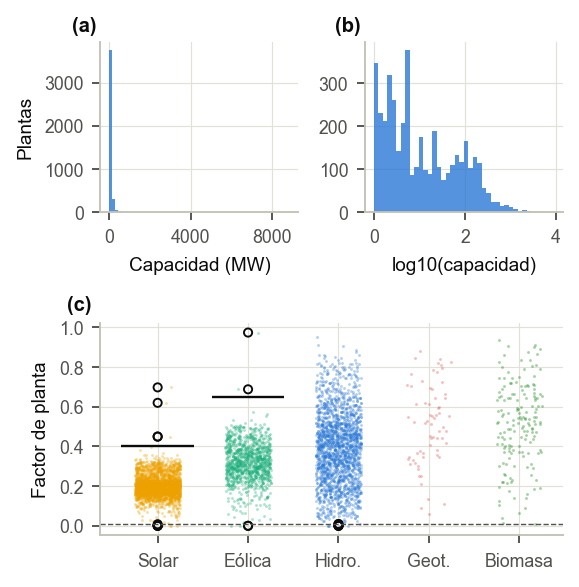

In [16]:
win = ce_exp.named_transformers_["num"]["winsor"]
limites = pd.DataFrame({"límite inferior (p0.5)": win.lim_inf_, "límite superior (p99.5)": win.lim_sup_}, index=VARS_NUM)
for c, X_c in zip(ORDEN_CONJ, (X_ent, X_val, X_pru)):
    vals = X_c[VARS_NUM]
    limites[f"% recortado · {c}"] = ((vals.lt(win.lim_inf_) | vals.gt(win.lim_sup_)).mean() * 100).values
display(Markdown("**Límites de winsorización aprendidos en entrenamiento y % de valores recortados en cada conjunto**"))
display(limites.style.format("{:.3f}"))

# Figura 1: los tres tratamientos de atípicos
with plt.rc_context(ESTILO_INFORME):
    # Formato de una columna del informe: (a) y (b) arriba, (c) abajo a todo el ancho
    fig = plt.figure(figsize=(ANCHO_COLUMNA, 3.5))
    rejilla = fig.add_gridspec(2, 2, height_ratios=[1, 1.25])
    axes = [fig.add_subplot(rejilla[0, 0]), fig.add_subplot(rejilla[0, 1]), fig.add_subplot(rejilla[1, :])]
    cap = 10 ** X_ent["log_capacidad"]
    axes[0].hist(cap, bins=60, color=AZUL, alpha=0.8)
    axes[0].set_xticks([0, 4000, 8000])
    axes[0].set_xlabel("Capacidad (MW)"); axes[0].set_ylabel("Plantas")
    axes[1].hist(X_ent["log_capacidad"], bins=40, color=AZUL, alpha=0.8)
    axes[1].set_xlabel("log10(capacidad)")
    for t in TEC_MODELO:
        datos_t = d2.loc[d2["tecnologia"] == t, "factor_planta_prom"]
        pos = TEC_MODELO.index(t)
        axes[2].scatter(np.full(len(datos_t), pos) + rng.uniform(-0.25, 0.25, len(datos_t)), datos_t, s=1.5,
                        color=TEC_COLOR[t], alpha=0.35, linewidths=0)
        if t in LIMITE_SUPERIOR_FP:
            axes[2].hlines(LIMITE_SUPERIOR_FP[t], pos - 0.4, pos + 0.4, color=TINTA, linewidth=1)
    malos = retiradas.assign(pos=retiradas["tecnologia"].astype(str).map(TEC_MODELO.index))
    axes[2].scatter(malos["pos"], malos["factor_planta_prom"], s=12, facecolors="none", edgecolors=TINTA, linewidths=0.8)
    axes[2].axhline(LIMITE_INFERIOR_FP, color=TINTA2, linewidth=0.6, linestyle="--")
    axes[2].set_xticks(range(len(TEC_MODELO)), ["Solar", "Eólica", "Hidro.", "Geot.", "Biomasa"])
    axes[2].set_ylabel("Factor de planta")
    for ax, letra in zip(axes, ["(a)", "(b)", "(c)"]):
        etiqueta_panel(ax, letra)
    fig.tight_layout()
    guardar_fig2(fig, "fig1_tratamiento_atipicos.png")
    plt.show()

**Figura 1.** (a) La capacidad en escala lineal: unas pocas centrales gigantes. (b) La misma variable en log10, casi simétrica: las plantas grandes se conservan, pero dejan de dominar. (c) Factor de planta por tecnología con los límites físicos (líneas negras: solar 0.40 y eólica 0.65; línea discontinua: FP = 0.01); los círculos son las plantas retiradas en §2.2.

**Lectura de la winsorización.** Los límites aprendidos en entrenamiento tienen sentido físico: la capacidad se recorta entre 1 MW y ≈ 1 050 MW ($10^{3.02}$), la irradiación relativa entre 0.525 y 0.985 (latitudes de ≈ 58° y ≈ 10°) y la edad entre 1 y 110 años. Solo se recorta entre el 0.3 % y el 1.1 % de los valores de cada variable, con porcentajes parecidos en los tres conjuntos: los límites se trasladan bien a datos no vistos y no deforman las distribuciones.

## 5.4 Evidencia de las variables derivadas (solo entrenamiento)

Antes de usarlas se verifica, **solo con el entrenamiento**, que las variables derivadas se asocian con el factor de planta en la dirección que predice el dominio. Como la §7.3 de la Fase 1 mostró que los efectos cambian de signo según la tecnología, la correlación se calcula dentro de cada una. Esa es también la justificación de las **interacciones tecnología × variable** que añade el *pipeline*: en un modelo lineal, el coeficiente de `irradiacion_relativa` es la pendiente de la solar (la referencia) y cada interacción es cuánto cambia esa pendiente en otra tecnología.

In [17]:
filas_ev = []
ent_ev = X_ent.assign(fp=y_ent)
for t, g in ent_ev.groupby("tecnologia"):
    for v in VARS_DERIVADAS:
        sub = g[[v, "fp"]].dropna()
        rho, p = stats.spearmanr(sub[v], sub["fp"])
        filas_ev.append({"tecnología": t, "variable": v, "ρ": rho, "p": p, "n": len(sub)})
ev = pd.DataFrame(filas_ev)
tabla_ev = ev.pivot(index="tecnología", columns="variable", values="ρ").reindex(TEC_MODELO)[VARS_DERIVADAS]
signif = ev.pivot(index="tecnología", columns="variable", values="p").reindex(TEC_MODELO)[VARS_DERIVADAS] < 0.05
display(Markdown("**ρ de Spearman entre cada variable derivada y el FP, dentro de cada tecnología (entrenamiento; * = p < 0.05) · Tabla IV**"))
display(tabla_ev.round(2).astype(str).where(~signif, tabla_ev.round(2).astype(str) + " *"))
print("n por tecnología:", ent_ev["tecnologia"].value_counts().reindex(TEC_MODELO).to_dict())

**ρ de Spearman entre cada variable derivada y el FP, dentro de cada tecnología (entrenamiento; * = p < 0.05) · Tabla IV**

variable,log_capacidad,edad_planta,irradiacion_relativa,densidad_misma_tec
tecnología,,,,
Solar,0.38 *,-0.08 *,0.49 *,-0.19 *
Eólica,0.29 *,-0.46 *,0.15 *,-0.1 *
Hidroeléctrica,-0.13 *,0.02,-0.1 *,0.05 *
Geotérmica,0.19,0.2,0.11,0.23
Biomasa,0.12,0.28 *,0.18,-0.04


n por tecnología: {'Solar': 1886, 'Eólica': 781, 'Hidroeléctrica': 1374, 'Geotérmica': 46, 'Biomasa': 115}


**Contraste de las hipótesis (Tabla IV)**

- **`irradiacion_relativa` se confirma** como el mejor indicador del recurso solar: ρ = **+0.49** en la solar, la asociación más fuerte de la tabla. En la eólica es débil (+0.15) y en la hidroeléctrica se invierte (−0.10): las hidroeléctricas de latitudes altas, alimentadas por deshielo, rinden algo más.
- **`log_capacidad` se confirma** en la solar (+0.38) y la eólica (+0.29), y se **invierte** en la hidroeléctrica (−0.13): las grandes centrales con embalse suelen operar en las horas de mayor demanda (punta) y no todo el día, lo que baja su FP.
- **`edad_planta` se confirma** en la eólica (−0.46: los parques antiguos tienen turbinas más bajas y pequeñas) y, débilmente, en la solar (−0.08, compatible con la degradación de los paneles). En la biomasa es positiva (+0.28): las plantas antiguas de biomasa suelen operar de forma continua.
- **`densidad_misma_tec` se refuta** en su dirección: en la solar (−0.19) y en la eólica (−0.10) **más vecinas implican menor FP**, al revés de lo esperado. Una explicación probable es que en EE. UU. la concentración de plantas responde más a incentivos estatales y a la cercanía a la demanda que a la calidad del recurso (por ejemplo, muchas solares pequeñas en el noreste, con poco sol). Se conserva porque contiene información, pero su utilidad se reevaluará en la Fase 3; en el modelo base no resulta significativa tras controlar por las demás (§7.3).
- En la geotérmica (46 plantas) y la biomasa (115) casi nada es significativo por tamaño de muestra.
- **Conclusión**: los signos cambian de una tecnología a otra (la edad baja el FP eólico y sube el de la biomasa; la latitud sube el FP solar y baja el hidroeléctrico). Un modelo lineal sin interacciones promediaría esos efectos opuestos, como ocurrió en la §9.2 de la Fase 1. Por eso el *pipeline* añade las interacciones tecnología × {irradiación, edad, capacidad}.

## 5.5 Codificación, escalamiento y *pipeline* completo

**Codificación de las variables categóricas**

| Variable | Tipo | Codificación | Por qué | Cómo se evita la fuga |
|---|---|---|---|---|
| `tecnologia` | Nominal, 5 categorías | **One-Hot** con la solar como referencia (`drop="first"`) | Pocas categorías sin orden; con la referencia, cada coeficiente es la diferencia frente a una planta solar equivalente | Las categorías se fijan de antemano (no dependen de la muestra) |
| `country` | Nominal, alta cardinalidad y muy desbalanceada (88 % EE. UU.) | **Target Encoding** (`TargetEncoder`) | One-Hot crearía decenas de columnas casi vacías. El Target Encoding reemplaza cada país por el FP medio de sus plantas, suavizado hacia la media global cuando el país tiene pocas plantas (Micci-Barreca, 2001) | Se ajusta solo con entrenamiento y, dentro de él, con **validación cruzada interna de 5 pliegues** (*cross-fitting*): la codificación de cada planta se calcula sin su propio FP |
| `nivel_desempeno` (objetivo de PS2) | Ordinal: Bajo < Medio < Alto | **Ordinal** (0, 1, 2) para conservar el orden en el reporte | Permite medir cuántos niveles se equivoca el modelo, no solo si acierta | Los cortes se calculan solo con entrenamiento (§6) |
| `zona_climatica`, `rango_capacidad` | Ordinales | No entran al modelo base | Son discretizaciones de `irradiacion_relativa` y `log_capacidad` (§2.3); se conservan para describir y para los modelos de árboles de la Fase 3 | — |

**Escalamiento.** Se usa `StandardScaler` (media 0, desviación 1) porque (i) los coeficientes del modelo lineal y de la logística quedan en la misma escala y se pueden comparar, (ii) la distancia del `KNNImputer` no queda dominada por la variable de mayor rango, y (iii) la regularización de la Fase 3 (Ridge, Lasso) lo exige. `RobustScaler` sería preferible con colas pesadas, pero la transformación log y la *winsorización* previas ya las controlan. La media y la desviación se estiman solo con entrenamiento (verificado en §8).

**Orden del *pipeline*:** codificar y escalar → imputar con el método elegido (+ indicador de falta) → crear las interacciones con los valores ya imputados → modelo. Al ser un único objeto de scikit-learn, `fit` solo ve entrenamiento y `predict` aplica las mismas transformaciones a datos nuevos, lo que también servirá para el módulo de predicción del tablero (Fase 4).

In [18]:
class Interacciones(BaseEstimator, TransformerMixin):
    # Añade los productos tecnología × variable (la solar es la referencia). No estima parámetros.
    def __init__(self, variables=("irradiacion_relativa", "edad_planta", "log_capacidad")):
        self.variables = variables

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        self.dummies_ = [c for c in X.columns if c.startswith("tecnologia_")]
        return self

    def transform(self, X):
        X = X.copy()
        for d in self.dummies_:
            for v in self.variables:
                X[f"{d.removeprefix('tecnologia_')} × {v}"] = X[d] * X[v]
        return X

    def get_feature_names_out(self, input_features=None):
        nuevas = [f"{d.removeprefix('tecnologia_')} × {v}" for d in self.dummies_ for v in self.variables]
        return np.concatenate([self.feature_names_in_, nuevas])


def preprocesador(tipo_objetivo="continuous", interacciones=True):
    pasos = [("codificar_escalar", codificador_escalador(tipo_objetivo)), ("imputar", clone(IMPUTADOR))]
    if interacciones:
        pasos.append(("interacciones", Interacciones()))
    return Pipeline(pasos).set_output(transform="pandas")


prep_demo = preprocesador().fit(X_ent, y_ent)
Xt_demo = prep_demo.transform(X_val)
print(f"Columnas que recibe el modelo ({Xt_demo.shape[1]}):")
print(", ".join(Xt_demo.columns))
display(Markdown("**Primeras filas de validación ya transformadas** (codificadas, escaladas, imputadas y con interacciones)"))
display(Xt_demo.head(4).round(3))

te = prep_demo.named_steps["codificar_escalar"].named_transformers_["pais"]
cod_pais = pd.Series(te.encodings_[0], index=te.categories_[0], name="FP codificado")
n_pais = X_ent["country"].value_counts()
display(Markdown(f"**Target Encoding del país** (media global de entrenamiento = {y_ent.mean():.3f}; los países con pocas plantas se acercan a ella)"))
display(pd.DataFrame({"plantas en entrenamiento": n_pais, "FP medio observado": y_ent.groupby(X_ent["country"]).mean(),
                      "FP codificado": cod_pais}).loc[n_pais.index[:8]].round(3))

Columnas que recibe el modelo (22):
tecnologia_Eólica, tecnologia_Hidroeléctrica, tecnologia_Geotérmica, tecnologia_Biomasa, country, log_capacidad, irradiacion_relativa, densidad_misma_tec, edad_planta, missingindicator_edad_planta, Eólica × irradiacion_relativa, Eólica × edad_planta, Eólica × log_capacidad, Hidroeléctrica × irradiacion_relativa, Hidroeléctrica × edad_planta, Hidroeléctrica × log_capacidad, Geotérmica × irradiacion_relativa, Geotérmica × edad_planta, Geotérmica × log_capacidad, Biomasa × irradiacion_relativa, Biomasa × edad_planta, Biomasa × log_capacidad


**Primeras filas de validación ya transformadas** (codificadas, escaladas, imputadas y con interacciones)

,tecnologia_Eólica,tecnologia_Hidroeléctrica,tecnologia_Geotérmica,tecnologia_Biomasa,country,log_capacidad,irradiacion_relativa,densidad_misma_tec,edad_planta,missingindicator_edad_planta,Eólica × irradiacion_relativa,Eólica × edad_planta,Eólica × log_capacidad,Hidroeléctrica × irradiacion_relativa,Hidroeléctrica × edad_planta,Hidroeléctrica × log_capacidad,Geotérmica × irradiacion_relativa,Geotérmica × edad_planta,Geotérmica × log_capacidad,Biomasa × irradiacion_relativa,Biomasa × edad_planta,Biomasa × log_capacidad
146,0.000,1.000,0.000,0.000,0.333,0.508,0.495,-1.199,1.617,1.000,0.000,0.000,0.000,0.495,1.617,0.508,0.000,0.000,0.000,0.000,0.000,0.000
164,0.000,1.000,0.000,0.000,0.333,0.250,-0.662,-0.390,1.630,1.000,-0.000,0.000,0.000,-0.662,1.630,0.250,-0.000,0.000,0.000,-0.000,0.000,0.000
165,1.000,0.000,0.000,0.000,0.333,0.288,0.012,-0.790,-0.354,1.000,0.012,-0.354,0.288,0.000,-0.000,0.000,0.000,-0.000,0.000,0.000,-0.000,0.000
212,0.000,1.000,0.000,0.000,0.333,1.442,-0.604,-0.169,1.350,1.000,-0.000,0.000,0.000,-0.604,1.350,1.442,-0.000,0.000,0.000,-0.000,0.000,0.000


**Target Encoding del país** (media global de entrenamiento = 0.298; los países con pocas plantas se acercan a ella)

,plantas en entrenamiento,FP medio observado,FP codificado
country,,,
USA,3712,0.288,0.288
IND,120,0.339,0.339
VNM,107,0.477,0.477
AUS,77,0.333,0.333
GTM,30,0.429,0.425
ITA,30,0.171,0.174
MMR,14,0.515,0.497
AUT,14,0.347,0.339


**Lectura del *pipeline***

- El modelo recibe **22 columnas**: 4 indicadoras de tecnología, el país codificado, las 4 variables numéricas escaladas, el indicador de falta del año y 12 interacciones. Las filas de ejemplo muestran el efecto de cada paso: las variables numéricas están en unidades de desviación estándar, el país en unidades de FP y las interacciones valen 0 salvo para la tecnología de la planta.
- **El Target Encoding suaviza los países con pocas plantas**: EE. UU., con 3 712 plantas, conserva su FP medio (0.288); Myanmar, con 14, baja de 0.515 a 0.497 y Austria, con 14, de 0.347 a 0.339, acercándose a la media global (0.298). Es la protección contra el sobreajuste a países con muy pocos datos. El entrenamiento contiene 30 países; un país nuevo recibiría la media global.

# 6. Variable objetivo de clasificación y desbalance de clases (Actividad 4)

En la Fase 1 los terciles se calcularon con las 6 031 plantas (§4.2 de la Fase 1), lo que sirve para describir pero no para modelar: usar el FP de validación y prueba para fijar los cortes sería fuga de datos. Aquí los cortes se recalculan **solo con el FP de entrenamiento** y se aplican a los tres conjuntos.

In [19]:
cortes_f2 = y_ent.quantile([1 / 3, 2 / 3]).values
cortes_f1 = df_fp["factor_planta_prom"].quantile([1 / 3, 2 / 3]).values


def a_nivel(fp):
    # Mismo criterio que en la Fase 1 (intervalos cerrados por la derecha), con cortes de entrenamiento
    return pd.cut(fp, [-np.inf, *cortes_f2, np.inf], labels=NIVELES).astype(str)


yc_ent, yc_val, yc_pru = a_nivel(y_ent), a_nivel(y_val), a_nivel(y_pru)
codif_nivel = OrdinalEncoder(categories=[NIVELES]).fit(pd.DataFrame({"nivel": NIVELES}))
print(f"Cortes de entrenamiento: Bajo ≤ {cortes_f2[0]:.3f} < Medio ≤ {cortes_f2[1]:.3f} < Alto")
print(f"Cortes descriptivos de la Fase 1 (todas las plantas): {cortes_f1[0]:.3f} y {cortes_f1[1]:.3f}")
print("Codificación ordinal del objetivo:", dict(zip(NIVELES, codif_nivel.transform(pd.DataFrame({"nivel": NIVELES})).ravel().astype(int))))

dist_clases = pd.DataFrame({c: pd.Series(yc).value_counts(normalize=True).reindex(NIVELES) * 100
                            for c, yc in zip(ORDEN_CONJ, (yc_ent, yc_val, yc_pru))})
dist_clases.loc["razón mayoritaria / minoritaria"] = [pd.Series(yc).value_counts().max() / pd.Series(yc).value_counts().min()
                                                      for yc in (yc_ent, yc_val, yc_pru)]
display(Markdown("**Distribución de las clases por conjunto (%) y razón de desbalance**"))
display(dist_clases.round(2))
display(Markdown("**Clases dentro de cada tecnología, entrenamiento (% por fila)**"))
display((pd.crosstab(X_ent["tecnologia"], yc_ent, normalize="index")[NIVELES] * 100).reindex(TEC_MODELO).round(1))

Cortes de entrenamiento: Bajo ≤ 0.205 < Medio ≤ 0.323 < Alto
Cortes descriptivos de la Fase 1 (todas las plantas): 0.205 y 0.324
Codificación ordinal del objetivo: {'Bajo': np.int64(0), 'Medio': np.int64(1), 'Alto': np.int64(2)}


**Distribución de las clases por conjunto (%) y razón de desbalance**

,entrenamiento,validación,prueba
factor_planta_prom,,,
Bajo,33.340,33.480,32.750
Medio,33.320,33.150,33.520
Alto,33.340,33.370,33.740
razón mayoritaria / minoritaria,1.000,1.010,1.030


**Clases dentro de cada tecnología, entrenamiento (% por fila)**

factor_planta_prom,Bajo,Medio,Alto
tecnologia,,,
Solar,57.500,41.300,1.300
Eólica,9.000,43.300,47.800
Hidroeléctrica,17.000,19.400,63.600
Geotérmica,6.500,10.900,82.600
Biomasa,8.700,11.300,80.000


**Interpretación del objetivo de clasificación y del desbalance**

- **Cortes de entrenamiento**: Bajo ≤ 0.205 < Medio ≤ 0.323 < Alto. Son casi idénticos a los descriptivos de la Fase 1 (0.205 y 0.324), señal de que el entrenamiento representa bien al conjunto. Aun así, el procedimiento es el que importa: en otra muestra los cortes de todo el conjunto sí podrían filtrar información de la prueba.
- **No hay desbalance que tratar.** Por construcción con terciles, las clases están balanceadas en entrenamiento (33.3 % cada una) y casi en validación y prueba (razón mayoritaria / minoritaria ≤ 1.03). Las técnicas que menciona la guía (SMOTE, Chawla et al., 2002; ADASYN, He et al., 2008; o `class_weight`) están pensadas para desbalances severos (por ejemplo, 1:10). Aplicarlas aquí no corregiría nada y crearía plantas sintéticas que no existen. **Decisión: no se aplica remuestreo.** Si se aplicara en el futuro, iría dentro del *pipeline* y solo sobre los pliegues de entrenamiento.
- **El desequilibrio dentro de cada tecnología es señal, no desbalance**: solo el 1.3 % de las solares es *Alto*, frente al 80–83 % de la biomasa y la geotérmica. Es exactamente lo que el modelo debe aprender. Remuestrear para "igualar" esas proporciones borraría la relación entre tecnología y rendimiento que se quiere predecir.

# 7. Modelos base (Actividad 4)

Un modelo base (*baseline*) fija el **umbral mínimo de rendimiento**: un modelo de la Fase 3 que no lo supere no aporta nada, por sofisticado que sea. Se usan dos niveles de referencia, como pide la guía:

- **Referencias triviales** (`DummyRegressor`, `DummyClassifier`): ignoran los predictores. Responden a "¿cuánto se acierta sin modelo?".
- **Modelos base oficiales**: **regresión lineal** (PS1) y **regresión logística básica** (PS2) con el *pipeline* completo de §5. Son interpretables y rápidos, y sus supuestos se pueden diagnosticar.

Además se incluyen dos modelos lineales intermedios para medir el aporte de la ingeniería de variables (estudio de ablación): uno solo con la tecnología y otro con las variables y la imputación de la Fase 1 (§9.3 de la Fase 1).

**Protocolo de evaluación.** Los modelos se ajustan con entrenamiento; las comparaciones se hacen en **validación** y con validación cruzada de 5 pliegues **agrupada por sitio** dentro del entrenamiento. El conjunto de **prueba** se usa una sola vez, en §7.6, para registrar la métrica inicial oficial.

**Métricas.** En regresión: R² (proporción de la varianza del FP explicada), RMSE (penaliza más los errores grandes) y MAE (error típico en puntos de FP), todos sobre datos que el modelo no vio. En clasificación: *accuracy*, *accuracy* balanceada y **F1-macro** (promedio del F1 de las tres clases, la métrica de la meta SMART), más la matriz de confusión.

## 7.1 Regresión del factor de planta (PS1)

In [20]:
cv_grupos = GroupKFold(n_splits=5)
ref_fase1 = ColumnTransformer([
    ("tec", OneHotEncoder(categories=[TEC_MODELO], drop="first", sparse_output=False), ["tecnologia"]),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("esc", StandardScaler())]),
     ["log_capacidad", "latitude", "longitude", "latitud_abs", "edad_planta"])])

MODELOS_REG = {
    "R0 · Dummy (media de entrenamiento)": DummyRegressor(strategy="mean"),
    "R1 · Lineal simple (solo tecnología)": Pipeline([
        ("prep", ColumnTransformer([("tec", OneHotEncoder(categories=[TEC_MODELO], drop="first", sparse_output=False), ["tecnologia"])])),
        ("modelo", LinearRegression())]),
    "R2 · Lineal múltiple (variables de la Fase 1)": Pipeline([("prep", ref_fase1), ("modelo", LinearRegression())]),
    "R3 · Lineal múltiple + ingeniería de la Fase 2 (BASE)": Pipeline([("prep", preprocesador()), ("modelo", LinearRegression())]),
}


def metricas_reg(y, pred):
    return {"R²": r2_score(y, pred), "RMSE": np.sqrt(mean_squared_error(y, pred)), "MAE": mean_absolute_error(y, pred)}


filas_reg = []
for nombre, modelo in MODELOS_REG.items():
    modelo.fit(X_ent, y_ent)
    r2_cv = cross_val_score(modelo, X_ent, y_ent, groups=grupos_ent, cv=cv_grupos, scoring="r2")
    m_val, m_ent = metricas_reg(y_val, modelo.predict(X_val)), metricas_reg(y_ent, modelo.predict(X_ent))
    filas_reg.append({"modelo": nombre, "R² entrenamiento": m_ent["R²"], "R² CV (media)": r2_cv.mean(), "R² CV (desv.)": r2_cv.std(),
                      "R² validación": m_val["R²"], "RMSE validación": m_val["RMSE"], "MAE validación": m_val["MAE"]})
res_reg_f2 = pd.DataFrame(filas_reg)
modelo_reg_base = MODELOS_REG["R3 · Lineal múltiple + ingeniería de la Fase 2 (BASE)"]
display(Markdown("**Modelos de regresión: entrenamiento, validación cruzada agrupada y validación (Tabla V)**"))
res_reg_f2.style.format({c: "{:.3f}" for c in res_reg_f2.columns if c != "modelo"}).hide(axis="index")

**Modelos de regresión: entrenamiento, validación cruzada agrupada y validación (Tabla V)**

modelo,R² entrenamiento,R² CV (media),R² CV (desv.),R² validación,RMSE validación,MAE validación
R0 · Dummy (media de entrenamiento),0.000,-0.000,0.000,-0.000,0.154,0.121
R1 · Lineal simple (solo tecnología),0.380,0.377,0.027,0.369,0.122,0.085
R2 · Lineal múltiple (variables de la Fase 1),0.397,0.390,0.031,0.386,0.120,0.082
R3 · Lineal múltiple + ingeniería de la Fase 2 (BASE),0.498,0.469,0.016,0.489,0.110,0.074


**Interpretación de los modelos de regresión (Tabla V)**

- **El modelo base explica el 49 % de la varianza del FP en validación** (R² = 0.489; validación cruzada 0.469 ± 0.016), con un error típico de **7.4 puntos de FP** (MAE = 0.074) y RMSE = 0.110. Frente al *Dummy*, que predice la media para todas las plantas, el RMSE baja un 29 % (de 0.154 a 0.110) y el MAE un 39 % (de 0.121 a 0.074).
- **La ablación muestra de dónde viene el rendimiento:**
  - La tecnología sola explica el 37 % (R1). Es el hallazgo central de la Fase 1, ahora como predicción.
  - Las variables de la Fase 1 (capacidad, latitud, longitud y año, imputado con la mediana) suman menos de 2 puntos (R2 = 0.386): sin interacciones, sus efectos opuestos entre tecnologías se cancelan.
  - La **ingeniería de la Fase 2** (irradiación, edad, densidad, codificación del país, imputación KNN e interacciones) suma **10 puntos** de R² (de 0.386 a 0.489). Es la evidencia de que las variables derivadas aportan.
- **No hay sobreajuste**: el R² de entrenamiento (0.498) es apenas mayor que el de validación cruzada (0.469) y el de validación (0.489). Con 22 coeficientes y más de 4 000 plantas, el modelo lineal no tiene capacidad para memorizar.

## 7.2 Diagnóstico del modelo base de regresión

Un modelo lineal se interpreta con confianza solo si sus residuos se comportan bien. Se revisa en validación: (a) valores predichos frente a observados, (b) residuos frente a predichos (patrones = no linealidad; embudo = heterocedasticidad), (c) gráfico Q-Q de normalidad y (d) residuos por tecnología. La heterocedasticidad se prueba con Breusch-Pagan (1979) en entrenamiento.

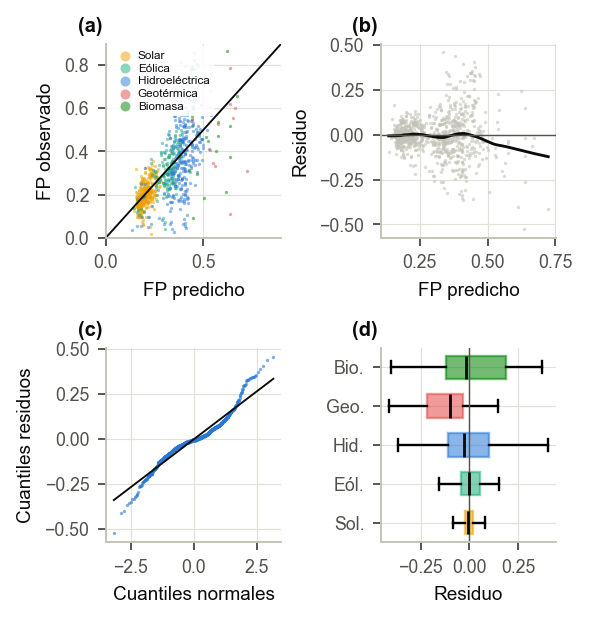

Breusch-Pagan: LM = 908.1, p = 6.76e-178 → heterocedasticidad
Asimetría de los residuos (validación) = 0.23 | curtosis en exceso = 3.08
Error medio por tecnología en validación (sesgo; + = el modelo subestima):
                sesgo medio  mediana  RMSE
tecnologia                                
Solar                -0.002   -0.005 0.044
Eólica                0.000   -0.004 0.072
Hidroeléctrica       -0.003   -0.027 0.157
Geotérmica           -0.133   -0.097 0.235
Biomasa               0.012   -0.016 0.223


In [21]:
pred_val = modelo_reg_base.predict(X_val)
resid_val = y_val - pred_val
tec_val = X_val["tecnologia"]

with plt.rc_context(ESTILO_INFORME):
    fig, axes = plt.subplots(2, 2, figsize=(ANCHO_COLUMNA, 3.7))      # formato de una columna del informe
    ax = axes[0, 0]
    for t in TEC_MODELO:
        msk = tec_val == t
        ax.scatter(pred_val[msk], y_val[msk], s=2, color=TEC_COLOR[t], alpha=0.5, linewidths=0, label=t)
    ax.plot([0, 1], [0, 1], color=TINTA, linewidth=0.8)
    ax.set_xlim(0, 0.9); ax.set_ylim(0, 0.9)
    ax.set_xlabel("FP predicho"); ax.set_ylabel("FP observado")
    ax.legend(markerscale=3, fontsize=5, loc="upper left", handletextpad=0.1, borderaxespad=0.2, labelspacing=0.2,
              frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
    ax = axes[0, 1]
    ax.scatter(pred_val, resid_val, s=2, color=GRIS, alpha=0.6, linewidths=0)
    suav = lowess(resid_val, pred_val, frac=0.3)
    ax.plot(suav[:, 0], suav[:, 1], color=TINTA, linewidth=1.2)
    ax.axhline(0, color=TINTA2, linewidth=0.6)
    ax.set_xlabel("FP predicho"); ax.set_ylabel("Residuo")
    ax = axes[1, 0]
    (osm, osr), (pend, inter, _) = stats.probplot(resid_val, dist="norm")
    ax.scatter(osm, osr, s=2, color=AZUL, alpha=0.6, linewidths=0)
    ax.plot(osm, pend * osm + inter, color=TINTA, linewidth=0.8)
    ax.set_xlabel("Cuantiles normales"); ax.set_ylabel("Cuantiles residuos")
    ax = axes[1, 1]
    datos_r = [resid_val[tec_val == t] for t in TEC_MODELO]
    bp = ax.boxplot(datos_r, vert=False, patch_artist=True, widths=0.6, showfliers=False,
                    medianprops=dict(color=TINTA, linewidth=1.2))
    for caja, t in zip(bp["boxes"], TEC_MODELO):
        caja.set(facecolor=TEC_COLOR[t], alpha=0.55, edgecolor=TEC_COLOR[t])
    ax.axvline(0, color=TINTA2, linewidth=0.6)
    ax.set_yticks(range(1, 6), ["Sol.", "Eól.", "Hid.", "Geo.", "Bio."]); ax.set_xlabel("Residuo")
    for a, letra in zip(axes.ravel(), ["(a)", "(b)", "(c)", "(d)"]):
        etiqueta_panel(a, letra)
    fig.tight_layout()
    guardar_fig2(fig, "fig2_diagnostico_regresion_base.png")
    plt.show()

# Pruebas formales sobre los residuos de entrenamiento
Xt_ent = clone(preprocesador()).fit_transform(X_ent, y_ent)     # misma representación con la que se ajustó el modelo
ols = sm.OLS(y_ent.values, sm.add_constant(Xt_ent.values)).fit(cov_type="HC3")   # errores robustos (ver §7.3)
bp_lm, bp_p, _, _ = het_breuschpagan(ols.resid, sm.add_constant(Xt_ent.values))
print(f"Breusch-Pagan: LM = {bp_lm:.1f}, p = {bp_p:.2e} → {'heterocedasticidad' if bp_p < 0.05 else 'varianza constante'}")
print(f"Asimetría de los residuos (validación) = {stats.skew(resid_val):.2f} | curtosis en exceso = {stats.kurtosis(resid_val):.2f}")
print("Error medio por tecnología en validación (sesgo; + = el modelo subestima):")
print(resid_val.groupby(tec_val).agg(["mean", "median", lambda s: np.sqrt((s ** 2).mean())])
      .set_axis(["sesgo medio", "mediana", "RMSE"], axis=1).reindex(TEC_MODELO).round(3).to_string())

**Figura 2.** Diagnóstico del modelo base de regresión en validación: (a) FP predicho frente a observado por tecnología (la diagonal es la predicción perfecta); (b) residuos frente a predichos con tendencia LOWESS; (c) gráfico Q-Q de los residuos; (d) residuos por tecnología.

**Interpretación del diagnóstico**

- **(a) El modelo comprime las predicciones.** Predice bien la nube solar (0.15–0.25), pero a las plantas de FP muy alto (hidroeléctricas y de biomasa con 0.6–0.85) les asigna 0.4–0.5: un modelo lineal regresa hacia la media cuando le faltan variables que distingan esos casos.
- **(b) Hay heterocedasticidad clara**: los residuos de las solares son pequeños y los de las predicciones entre 0.3 y 0.5 (hidroeléctricas, eólicas) son mucho más dispersos. Breusch-Pagan lo confirma (LM = 908, p ≈ 0). La tendencia LOWESS se mantiene en cero salvo en las predicciones más altas (> 0.5), donde el modelo sobreestima.
- **(c) Colas pesadas**: los residuos se apartan de la normal en los extremos (curtosis en exceso = 3.1).
- **(d) El error se concentra en las tecnologías gestionables o dependientes del agua**: RMSE de 0.044 en la solar y 0.072 en la eólica, frente a 0.157 en la hidroeléctrica, 0.223 en la biomasa y 0.235 en la geotérmica (esta última con solo 11 plantas en validación y un sesgo de −0.13). Su FP depende de variables que el conjunto de datos no tiene: la hidrología del año, el tipo de central (filo de agua o embalse), la disponibilidad de combustible y las decisiones de despacho.
- **Implicaciones**: (i) los supuestos de homocedasticidad y normalidad del modelo lineal no se cumplen, así que la inferencia sobre los coeficientes se hace con errores robustos (§7.3); las predicciones puntuales siguen siendo válidas, pero no sus intervalos clásicos. (ii) Para la Fase 3 se justifican modelos no lineales (ensambles de árboles) y posiblemente modelos o ponderaciones distintos por tecnología.

## 7.3 Coeficientes del modelo base: ¿qué aprendió?

Como los predictores numéricos están estandarizados, cada coeficiente es el cambio esperado del FP por **una desviación estándar** de la variable, con las demás constantes. Los coeficientes de tecnología son diferencias frente a una planta **solar** equivalente, y los de interacción, cuánto cambia la pendiente de la solar en cada otra tecnología. Los intervalos de confianza al 95 % salen del mismo ajuste por mínimos cuadrados (statsmodels), con **errores estándar robustos HC3** (MacKinnon y White, 1985), porque la §7.2 mostró que la varianza de los residuos no es constante y los errores clásicos serían demasiado optimistas. El país entra con su codificación en unidades de FP (no estandarizada): su coeficiente multiplica el FP medio del país.

In [22]:
coef = pd.DataFrame({"coeficiente": ols.params, "IC 2.5 %": ols.conf_int()[:, 0], "IC 97.5 %": ols.conf_int()[:, 1],
                     "p-valor": ols.pvalues}, index=["intercepto"] + list(Xt_ent.columns))
assert np.allclose(coef["coeficiente"].values[1:], modelo_reg_base.named_steps["modelo"].coef_, atol=1e-6), \
    "statsmodels y scikit-learn deben dar los mismos coeficientes"
coef["significativo (α=0.05)"] = np.where(coef["p-valor"] < 0.05, "Sí", "No")
print(f"R² del ajuste = {ols.rsquared:.3f} | R² ajustado = {ols.rsquared_adj:.3f} | {int(ols.df_model)} predictores | errores HC3")
print("(El R² del ajuste usa la codificación del país por validación cruzada con la que se entrenó; el «R² entrenamiento» de la "
      "Tabla V vuelve a predecir el entrenamiento con la codificación completa y por eso es algo mayor.)")
coef.reindex(coef["coeficiente"].abs().sort_values(ascending=False).index).style.format(
    {"coeficiente": "{:+.4f}", "IC 2.5 %": "{:+.4f}", "IC 97.5 %": "{:+.4f}", "p-valor": "{:.2e}"})

R² del ajuste = 0.479 | R² ajustado = 0.476 | 22 predictores | errores HC3
(El R² del ajuste usa la codificación del país por validación cruzada con la que se entrenó; el «R² entrenamiento» de la Tabla V vuelve a predecir el entrenamiento con la codificación completa y por eso es algo mayor.)


,coeficiente,IC 2.5 %,IC 97.5 %,p-valor,significativo (α=0.05)
country,+1.0803,+0.8933,+1.2673,1.02e-29,Sí
tecnologia_Biomasa,+0.3381,+0.2917,+0.3846,3.68e-46,Sí
tecnologia_Geotérmica,+0.3020,+0.1762,+0.4279,2.57e-06,Sí
Biomasa × edad_planta,+0.1988,+0.1004,+0.2972,7.51e-05,Sí
tecnologia_Hidroeléctrica,+0.1866,+0.1680,+0.2052,2.71e-86,Sí
Geotérmica × edad_planta,+0.1561,-0.0343,+0.3464,1.08e-01,No
intercepto,-0.1393,-0.1954,-0.0832,1.12e-06,Sí
Eólica × edad_planta,-0.1105,-0.1426,-0.0785,1.44e-11,Sí
Geotérmica × log_capacidad,+0.1080,-0.0908,+0.3068,2.87e-01,No
Hidroeléctrica × edad_planta,+0.0807,+0.0601,+0.1014,2.01e-14,Sí


**Interpretación de los coeficientes** (errores robustos HC3)

- **Tecnología** (frente a una planta solar con valores medios de las demás variables y en un país como EE. UU.): biomasa **+0.34**, geotérmica **+0.30**, hidroeléctrica **+0.19** y eólica **+0.07** puntos de FP, todas significativas. Reproducen el orden de la Fase 1 (§7.1 de la Fase 1), ahora como efectos ajustados por ubicación, escala y edad.
- **País**: coeficiente 1.08. Una planta de un país cuyo FP medio es 0.10 mayor tiene, en promedio, 0.11 más de FP. Recoge lo que la ubicación aporta más allá de la latitud (clima, regulación, tipo de flota).
- **Pendientes de la solar** (la referencia), por desviación estándar de cada variable:
  - **Irradiación +0.027**: acercarse 10° al ecuador (de 40° a 30°) sube el FP solar ≈ 4 puntos, coherente con la regresión simple de la Fase 1 (≈ 5 puntos, §9.1 de la Fase 1), ahora con las demás variables constantes.
  - **Capacidad +0.023** (una desviación equivale a multiplicar la capacidad por ≈ 6) y **edad −0.064**.
- **Las interacciones confirman los efectos que cambian con la tecnología** (§5.4):
  - **Eólica × edad = −0.111**: la pendiente de la edad en la eólica es −0.064 − 0.111 = −0.17 por desviación (≈ 28 años), es decir, unos **0.6 puntos de FP menos por cada año de antigüedad**. Es la mejora tecnológica de las turbinas que mostró la figura 4(b) de la Fase 1.
  - **Hidroeléctrica × irradiación = −0.060** y **× capacidad = −0.042**: en la hidroeléctrica las pendientes se invierten (−0.032 y −0.019): rinden más las de latitudes altas y las pequeñas.
  - **Biomasa × edad = +0.199**: las plantas de biomasa antiguas rinden más.
- **Indicador de falta del año = −0.074**: las plantas sin año reportado tienen 7 puntos menos de FP que plantas equivalentes con año. Confirma que la ausencia del dato no es neutra (§5.1) y justifica haber conservado el indicador.
- **No significativos**: la densidad (p = 0.17), todas las interacciones de la geotérmica (46 plantas) y dos de la biomasa. Son candidatos a regularización en la Fase 3 (Lasso).
- **Cautela**: los coeficientes describen asociaciones condicionadas, no causas. Por ejemplo, el efecto del país mezcla clima, regulación y composición de la flota.

## 7.4 Clasificación del nivel de desempeño (PS2)

**Modelos de clasificación: entrenamiento, validación cruzada agrupada y validación (Tabla VI)**

modelo,F1-macro entrenamiento,F1-macro CV (media),F1-macro CV (desv.),accuracy validación,accuracy balanceada validación,F1-macro validación
C0 · Dummy (clase más frecuente),0.167,0.157,0.004,0.334,0.333,0.167
C1 · Dummy (estratificado al azar),0.325,0.326,0.008,0.328,0.328,0.328
C2 · Logística básica + ingeniería de la Fase 2 (BASE),0.683,0.675,0.010,0.690,0.689,0.681


**Reporte por clase del modelo base en validación**

              precision    recall  f1-score   support

        Bajo      0.778     0.662     0.716       302
       Medio      0.639     0.508     0.566       299
        Alto      0.663     0.897     0.763       301

    accuracy                          0.690       902
   macro avg      0.693     0.689     0.681       902
weighted avg      0.694     0.690     0.682       902

Errores que saltan dos niveles (Bajo ↔ Alto): 5.2% de las plantas de validación


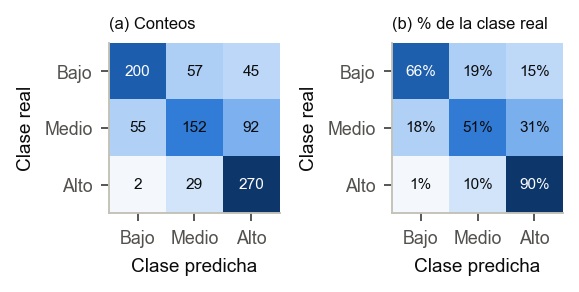

In [23]:
MODELOS_CLF = {
    "C0 · Dummy (clase más frecuente)": DummyClassifier(strategy="most_frequent"),
    "C1 · Dummy (estratificado al azar)": DummyClassifier(strategy="stratified", random_state=SEMILLA),
    "C2 · Logística básica + ingeniería de la Fase 2 (BASE)": Pipeline([
        ("prep", preprocesador("multiclass")), ("modelo", LogisticRegression(max_iter=5000))]),
}
cv_clf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)


def metricas_clf(y, pred):
    return {"accuracy": accuracy_score(y, pred), "accuracy balanceada": balanced_accuracy_score(y, pred),
            "F1-macro": f1_score(y, pred, average="macro")}


filas_clf = []
for nombre, modelo in MODELOS_CLF.items():
    modelo.fit(X_ent, yc_ent)
    f1_cv = cross_val_score(modelo, X_ent, yc_ent, groups=grupos_ent, cv=cv_clf, scoring="f1_macro")
    m_val = metricas_clf(yc_val, modelo.predict(X_val))
    filas_clf.append({"modelo": nombre, "F1-macro entrenamiento": f1_score(yc_ent, modelo.predict(X_ent), average="macro"),
                      "F1-macro CV (media)": f1_cv.mean(), "F1-macro CV (desv.)": f1_cv.std(),
                      **{f"{k} validación": v for k, v in m_val.items()}})
res_clf_f2 = pd.DataFrame(filas_clf)
modelo_clf_base = MODELOS_CLF["C2 · Logística básica + ingeniería de la Fase 2 (BASE)"]
display(Markdown("**Modelos de clasificación: entrenamiento, validación cruzada agrupada y validación (Tabla VI)**"))
display(res_clf_f2.style.format({c: "{:.3f}" for c in res_clf_f2.columns if c != "modelo"}).hide(axis="index"))

pred_c_val = modelo_clf_base.predict(X_val)
display(Markdown("**Reporte por clase del modelo base en validación**"))
print(classification_report(yc_val, pred_c_val, labels=NIVELES, digits=3))
salto = np.abs(codif_nivel.transform(pd.DataFrame({"nivel": yc_val.values})).ravel()
               - codif_nivel.transform(pd.DataFrame({"nivel": pred_c_val})).ravel())
print(f"Errores que saltan dos niveles (Bajo ↔ Alto): {(salto == 2).mean():.1%} de las plantas de validación")

with plt.rc_context(ESTILO_INFORME):
    fig, axes = plt.subplots(1, 2, figsize=(ANCHO_COLUMNA, 1.9))      # formato de una columna del informe
    mc = confusion_matrix(yc_val, pred_c_val, labels=NIVELES)
    for ax, matriz, titulo, fmt in [(axes[0], mc, "(a) Conteos", "{:.0f}"),
                                    (axes[1], mc / mc.sum(axis=1, keepdims=True), "(b) % de la clase real", "{:.0%}")]:
        ax.imshow(matriz, cmap=CMAP_SEQ)
        for i in range(3):
            for j in range(3):
                ax.text(j, i, fmt.format(matriz[i, j]), ha="center", va="center", fontsize=6.5,
                        color="white" if matriz[i, j] > matriz.max() * 0.6 else TINTA)
        ax.set_xticks(range(3), NIVELES); ax.set_yticks(range(3), NIVELES)
        ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real"); ax.grid(False)
        ax.set_title(titulo, fontsize=7, color=TINTA, loc="left")
    fig.tight_layout()
    guardar_fig2(fig, "fig3_confusion_clasificacion_base.png")
    plt.show()

**Figura 3.** Matriz de confusión del modelo base de clasificación en validación: conteos (izquierda) y porcentaje de cada clase real (derecha).

**Interpretación del modelo base de clasificación (Tabla VI y figura 3)**

- **F1-macro = 0.681 en validación** (validación cruzada 0.675 ± 0.010), frente a 0.167 del *Dummy* que predice siempre la clase más frecuente y 0.328 del que adivina al azar con las proporciones de las clases. La *accuracy* (0.690) y la *accuracy* balanceada (0.689) son casi iguales porque las clases están balanceadas. Entrenamiento (0.683) y validación cruzada (0.675) casi coinciden: no hay sobreajuste.
- **La clase *Alto* se reconoce muy bien** (90 % de *recall*): coincide con las tecnologías gestionables y con las hidroeléctricas, que el modelo identifica por la tecnología.
- ***Medio* es la más difícil** (51 % de *recall*; el 31 % se confunde con *Alto* y el 18 % con *Bajo*). Es una banda estrecha (FP entre 0.205 y 0.323, apenas 12 puntos) en la que se mezclan solares de buen sitio, eólicas e hidroeléctricas de bajo rendimiento, y en la frontera de una clase ordinal los errores son inevitables.
- **Errores graves**: solo el **5.2 %** de las plantas salta dos niveles (Bajo ↔ Alto); casi todas son plantas *Bajo* clasificadas como *Alto* (45), probablemente hidroeléctricas de bajo rendimiento que el modelo asigna al nivel típico de su tecnología.
- **Respuesta preliminar a PS2**: sí es posible clasificar el nivel de desempeño **sin usar la generación**, con un acierto de dos de cada tres plantas, pero un modelo lineal no basta para la meta de F1-macro ≥ 0.70.

## 7.5 ¿Sobreajuste, estabilidad y generalización fuera de EE. UU.?

Tres comprobaciones complementan las métricas puntuales:

1. **Curvas de aprendizaje** (validación cruzada agrupada dentro del entrenamiento; Hastie et al., 2009): si la curva de entrenamiento está muy por encima de la de validación, hay sobreajuste (varianza); si ambas se juntan en un valor bajo, hay subajuste (sesgo) y hacen falta modelos más flexibles.
2. **Estabilidad frente a la partición**: como recomendó el profesor en clase, no basta con correr el modelo una vez. Se repite **toda** la partición (y los cortes de las clases) con 10 semillas distintas y se observa si las métricas convergen.
3. **Generalización geográfica**: el 88 % de las plantas está en EE. UU. Se miden las métricas por separado dentro y fuera de EE. UU., y se hace una prueba de transferencia: entrenar **solo con plantas de EE. UU.** y predecir las plantas de validación de otros países.

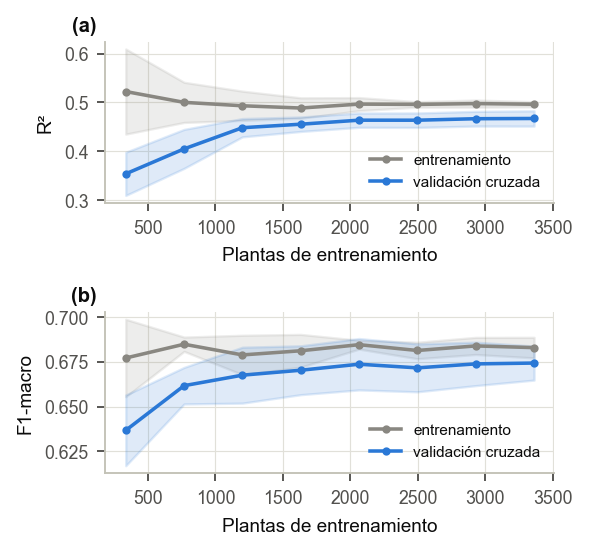

Regresión base (R²): con 3,361 plantas → entrenamiento 0.496, validación cruzada 0.467 (brecha 0.029)
Clasificación base (F1-macro): con 3,361 plantas → entrenamiento 0.683, validación cruzada 0.674 (brecha 0.009)


In [24]:
tam_curva = np.linspace(0.1, 1.0, 8)
curvas = {}
for clave, modelo, y_c, cv_c, metrica in [("Regresión base (R²)", modelo_reg_base, y_ent, cv_grupos, "r2"),
                                          ("Clasificación base (F1-macro)", modelo_clf_base, yc_ent, cv_clf, "f1_macro")]:
    n, s_ent, s_val = learning_curve(clone(modelo), X_ent, y_c, groups=grupos_ent, cv=cv_c, scoring=metrica,
                                     train_sizes=tam_curva, shuffle=True, random_state=SEMILLA)
    curvas[clave] = (n, s_ent, s_val)

with plt.rc_context(ESTILO_INFORME):
    fig, axes = plt.subplots(2, 1, figsize=(ANCHO_COLUMNA, 3.3))      # formato de una columna del informe
    for ax, (clave, (n, s_ent, s_val)), letra, eje_y in zip(axes, curvas.items(), ["(a)", "(b)"], ["R²", "F1-macro"]):
        for s, color, etiqueta in [(s_ent, TENUE, "entrenamiento"), (s_val, AZUL, "validación cruzada")]:
            ax.plot(n, s.mean(axis=1), "o-", color=color, markersize=2.5, label=etiqueta)
            ax.fill_between(n, s.mean(axis=1) - s.std(axis=1), s.mean(axis=1) + s.std(axis=1), color=color, alpha=0.15)
        ax.set_xlabel("Plantas de entrenamiento"); ax.set_ylabel(eje_y)
        ax.legend(loc="lower right", fontsize=6.5)
        etiqueta_panel(ax, letra)
    fig.tight_layout()
    guardar_fig2(fig, "fig4_curvas_aprendizaje.png")
    plt.show()
for clave, (n, s_ent, s_val) in curvas.items():
    print(f"{clave}: con {n[-1]:,} plantas → entrenamiento {s_ent[-1].mean():.3f}, validación cruzada {s_val[-1].mean():.3f} "
          f"(brecha {s_ent[-1].mean() - s_val[-1].mean():.3f})")

In [25]:
# (2) Estabilidad: se repite toda la partición con 10 semillas
filas_est = []
for semilla in range(10):
    conj = particionar(dm, semilla)
    e, v = dm[conj == "entrenamiento"], dm[conj == "validación"]
    Xe, Xv = (p[PREDICTORES].assign(tecnologia=p["tecnologia"].astype(str)) for p in (e, v))
    ye, yv = e[OBJETIVO], v[OBJETIVO]
    c_s = ye.quantile([1 / 3, 2 / 3]).values
    nivel = lambda s: pd.cut(s, [-np.inf, *c_s, np.inf], labels=NIVELES).astype(str)
    reg = clone(modelo_reg_base).fit(Xe, ye)
    clf = clone(modelo_clf_base).fit(Xe, nivel(ye))
    filas_est.append({"semilla": semilla, "R² validación": r2_score(yv, reg.predict(Xv)),
                      "RMSE validación": np.sqrt(mean_squared_error(yv, reg.predict(Xv))),
                      "F1-macro validación": f1_score(nivel(yv), clf.predict(Xv), average="macro")})
estab = pd.DataFrame(filas_est)
display(Markdown("**Estabilidad de los modelos base frente a 10 particiones distintas**"))
display(estab.drop(columns="semilla").agg(["mean", "std", "min", "max"]).rename(
    index={"mean": "media", "std": "desv. estándar", "min": "mínimo", "max": "máximo"}).round(3))

# (3) Generalización geográfica
es_eeuu_val = X_val["country"] == "USA"
geo = []
for grupo, msk in [("EE. UU.", es_eeuu_val), ("Resto del mundo", ~es_eeuu_val)]:
    geo.append({"subconjunto de validación": grupo, "plantas": int(msk.sum()),
                **{f"{k} (regresión)": v for k, v in metricas_reg(y_val[msk], pred_val[msk]).items()},
                "F1-macro (clasificación)": f1_score(yc_val[msk], pred_c_val[msk], average="macro")})
solo_eeuu = X_ent["country"] == "USA"
reg_eeuu = clone(modelo_reg_base).fit(X_ent[solo_eeuu], y_ent[solo_eeuu])
clf_eeuu = clone(modelo_clf_base).fit(X_ent[solo_eeuu], yc_ent[solo_eeuu])
geo.append({"subconjunto de validación": "Resto del mundo · modelo entrenado solo con EE. UU.", "plantas": int((~es_eeuu_val).sum()),
            **{f"{k} (regresión)": v for k, v in metricas_reg(y_val[~es_eeuu_val], reg_eeuu.predict(X_val[~es_eeuu_val])).items()},
            "F1-macro (clasificación)": f1_score(yc_val[~es_eeuu_val], clf_eeuu.predict(X_val[~es_eeuu_val]), average="macro")})
display(Markdown("**Generalización geográfica en validación**"))
display(pd.DataFrame(geo).style.format({c: "{:.3f}" for c in pd.DataFrame(geo).columns if c not in ("subconjunto de validación", "plantas")}).hide(axis="index"))
print("Tecnologías del resto del mundo en validación:", X_val.loc[~es_eeuu_val, "tecnologia"].value_counts().to_dict())

**Estabilidad de los modelos base frente a 10 particiones distintas**

,R² validación,RMSE validación,F1-macro validación
media,0.467,0.112,0.673
desv. estándar,0.022,0.003,0.017
mínimo,0.431,0.108,0.639
máximo,0.492,0.116,0.698


**Generalización geográfica en validación**

subconjunto de validación,plantas,R² (regresión),RMSE (regresión),MAE (regresión),F1-macro (clasificación)
EE. UU.,793,0.513,0.101,0.068,0.684
Resto del mundo,109,0.338,0.159,0.118,0.575
Resto del mundo · modelo entrenado solo con EE. UU.,109,-0.941,0.272,0.230,0.260


Tecnologías del resto del mundo en validación: {'Hidroeléctrica': 96, 'Eólica': 5, 'Biomasa': 4, 'Solar': 3, 'Geotérmica': 1}


**Figura 4.** Curvas de aprendizaje de los modelos base (media ± desviación de 5 pliegues agrupados por sitio): (a) regresión, R²; (b) clasificación, F1-macro.

**Interpretación**

- **Curvas de aprendizaje (figura 4): subajuste, no sobreajuste.** En regresión, con 3 361 plantas la brecha entre entrenamiento (0.496) y validación cruzada (0.467) es de solo 0.03; en clasificación, de 0.009. Ambas curvas se estabilizan a partir de unas 2 000 plantas. **Más datos del mismo tipo no mejorarían el modelo lineal**: su límite es el sesgo (no puede representar relaciones no lineales), no la varianza. Es el argumento cuantitativo para los modelos más flexibles de la Fase 3.
- **Estabilidad (10 particiones): los resultados no dependen de la semilla.** El R² de validación es 0.467 ± 0.022 (entre 0.431 y 0.492) y el F1-macro 0.673 ± 0.017 (entre 0.639 y 0.698). La partición de la semilla 42 quedó en el extremo favorable para la regresión (0.489), así que el valor esperado del modelo base es ≈ 0.47. Por eso, en la Fase 3 los modelos se compararán con validación cruzada y particiones repetidas, no con una sola partición.
- **Generalización geográfica: el principal punto débil.**
  - En EE. UU. (793 plantas de validación), R² = 0.513 y F1 = 0.684.
  - En el resto del mundo (109 plantas, 96 de ellas hidroeléctricas) el R² cae a **0.338** y el F1 a 0.575.
  - Si el modelo se entrena **solo con EE. UU.**, en otros países el R² es **−0.94** (peor que predecir la media) y el F1 0.26 (peor que el azar). Lo que el modelo aprende de EE. UU. no se traslada a las hidroeléctricas de otros climas (por ejemplo, las de Vietnam e India, con lluvias monzónicas, tienen FP medios de 0.48 y 0.34).
  - **Implicaciones**: incluir las plantas de otros países en el entrenamiento y codificar el país es imprescindible. Las conclusiones sobre Colombia (14 plantas, ninguna con generación) no se pueden extrapolar sin datos locales, y en la Fase 3 se evaluará el rendimiento por región.

## 7.6 Métrica inicial en el conjunto de prueba (umbral mínimo para la Fase 3)

Esta es la **única** vez que se usa el conjunto de prueba en la Fase 2. Ninguna decisión anterior (limpieza, variables, método de imputación, modelos) se tomó mirándolo. Las cifras quedan registradas como el umbral que los modelos de la Fase 3 deben superar, junto con las metas SMART de la Fase 1 (Tabla I del Entregable 1).

In [26]:
umbral = []
for nombre_m, modelo, X_c, y_c, tipo in [
        ("R0 · Dummy (media)", MODELOS_REG["R0 · Dummy (media de entrenamiento)"], X_pru, y_pru, "reg"),
        ("R3 · Regresión lineal (BASE)", modelo_reg_base, X_pru, y_pru, "reg"),
        ("C0 · Dummy (clase más frecuente)", MODELOS_CLF["C0 · Dummy (clase más frecuente)"], X_pru, yc_pru, "clf"),
        ("C2 · Regresión logística (BASE)", modelo_clf_base, X_pru, yc_pru, "clf")]:
    pred = modelo.predict(X_c)
    if tipo == "reg":
        m = metricas_reg(y_c, pred)
        umbral.append({"modelo": nombre_m, "tarea": "Regresión (PS1)", "métrica principal": "R²", "prueba": m["R²"],
                       "validación": r2_score(y_val, modelo.predict(X_val)), "meta SMART (OE2)": 0.55,
                       "otras métricas en prueba": f"RMSE = {m['RMSE']:.3f} · MAE = {m['MAE']:.3f}"})
    else:
        m = metricas_clf(y_c, pred)
        umbral.append({"modelo": nombre_m, "tarea": "Clasificación (PS2)", "métrica principal": "F1-macro", "prueba": m["F1-macro"],
                       "validación": f1_score(yc_val, modelo.predict(X_val), average="macro"), "meta SMART (OE2)": 0.70,
                       "otras métricas en prueba": f"accuracy = {m['accuracy']:.3f} · balanceada = {m['accuracy balanceada']:.3f}"})
umbral = pd.DataFrame(umbral)
umbral["¿alcanza la meta?"] = np.where(umbral["prueba"] >= umbral["meta SMART (OE2)"], "Sí", "No")
display(Markdown("**Umbral mínimo de rendimiento registrado en el conjunto de prueba (Tabla VII)**"))
umbral.style.format({"prueba": "{:.3f}", "validación": "{:.3f}", "meta SMART (OE2)": "{:.2f}"}).hide(axis="index")

**Umbral mínimo de rendimiento registrado en el conjunto de prueba (Tabla VII)**

modelo,tarea,métrica principal,prueba,validación,meta SMART (OE2),otras métricas en prueba,¿alcanza la meta?
R0 · Dummy (media),Regresión (PS1),R²,-0.000,-0.000,0.55,RMSE = 0.154 · MAE = 0.120,No
R3 · Regresión lineal (BASE),Regresión (PS1),R²,0.449,0.489,0.55,RMSE = 0.115 · MAE = 0.077,No
C0 · Dummy (clase más frecuente),Clasificación (PS2),F1-macro,0.168,0.167,0.70,accuracy = 0.337 · balanceada = 0.333,No
C2 · Regresión logística (BASE),Clasificación (PS2),F1-macro,0.671,0.681,0.70,accuracy = 0.678 · balanceada = 0.677,No


**Interpretación del umbral mínimo (Tabla VII)**

- **Métrica inicial oficial de la Fase 2:**
  - **Regresión (PS1)**: R² = **0.449**, RMSE = 0.115 y MAE = 0.077 en prueba con la regresión lineal, frente a R² ≈ 0 del *Dummy*.
  - **Clasificación (PS2)**: F1-macro = **0.671** con la regresión logística, frente a 0.168 del *Dummy*.
- **Prueba y validación son coherentes**: las cifras de prueba (0.449 y 0.671) caen dentro del rango de las 10 particiones de §7.5 (0.431–0.492 y 0.639–0.698), así que no hubo sobreajuste a la validación.
- **Ninguno de los dos modelos base alcanza las metas SMART** (R² ≥ 0.55; F1-macro ≥ 0.70). Faltan unos 0.10 de R² y 0.03 de F1. Es lo esperado: un modelo base fija el piso, no el techo. La prueba de concepto de la Fase 1 obtuvo R² = 0.59 y F1 = 0.75 con *gradient boosting* sin ajustar (§9.3 de la Fase 1), lo que indica que las metas son alcanzables con modelos no lineales. Habrá que confirmarlo con esta partición, más exigente porque agrupa por sitio y retira los valores imposibles.
- **Compromiso para la Fase 3**: un modelo avanzado se considerará útil solo si supera **R² > 0.449 y F1-macro > 0.671** en este mismo conjunto de prueba, con validación cruzada que confirme la mejora.

# 8. Auditoría de fuga de datos

La fuga de datos (*data leakage*) ocurre cuando el modelo recibe, durante el entrenamiento, información que no tendría al predecir una planta nueva; produce métricas optimistas que no se repiten en la práctica (Kaufman et al., 2012). Cada control de la tabla se verifica con código: si alguno fallara, la celda se detendría con un error.

In [27]:
controles = []


def control(nombre, como, condicion, evidencia):
    assert condicion, f"Falla el control: {nombre}"
    controles.append({"control": nombre, "cómo se garantiza": como, "verificación": evidencia})


prohibidas = set(COLS_GEN) | set(COLS_EST) | set(COLS_FP_ANUAL) | {"generacion_prom_gwh", "n_anios_generacion", "cv_generacion"}
control("Ningún predictor sale de la generación", "Criterio «¿se conoce antes de operar?» (§2.3)",
        not (prohibidas & set(PREDICTORES)), f"{len(prohibidas)} columnas prohibidas; 0 en los predictores")
control("Partición antes de cualquier ajuste", "Secciones 2–3 solo usan reglas y fórmulas fijas",
        True, "Ningún objeto se ajusta antes de §4")
control("Sitios no compartidos entre conjuntos", "Partición estratificada sobre los sitios (§4)",
        all(not (sitios[a] & sitios[b]) for a in ORDEN_CONJ for b in ORDEN_CONJ if a < b), "0 sitios en común")
esc = modelo_reg_base.named_steps["prep"].named_steps["codificar_escalar"].named_transformers_["num"]
media_ent = esc.named_steps["winsor"].transform(X_ent[VARS_NUM]).mean().values
control("Escalador ajustado solo con entrenamiento", "StandardScaler dentro del pipeline",
        np.allclose(esc.named_steps["esc"].mean_, media_ent, equal_nan=True),
        f"media del escalador = media de entrenamiento ({len(X_ent):,} plantas)")
imp = modelo_reg_base.named_steps["prep"].named_steps["imputar"]
control("Imputación ajustada solo con entrenamiento", "Método de imputación dentro del pipeline; no usa el FP",
        imp.n_features_in_ == len(Xt_ent.columns) - len([c for c in Xt_ent.columns if "×" in c or c.startswith("missingindicator")]),
        f"{type(imp).__name__}, ajustado con las {len(X_ent):,} plantas de entrenamiento")
te_m = modelo_reg_base.named_steps["prep"].named_steps["codificar_escalar"].named_transformers_["pais"]
control("Target Encoding sin fuga", "Ajuste con entrenamiento y validación cruzada interna (cross-fitting)",
        te_m.cv == 5 and len(te_m.categories_[0]) == X_ent["country"].nunique(),
        f"cv = {te_m.cv}; {len(te_m.categories_[0])} países vistos en entrenamiento")
control("Cortes de las clases con entrenamiento", "Terciles de y_ent (§6)",
        np.allclose(cortes_f2, y_ent.quantile([1 / 3, 2 / 3]).values),
        f"cortes {cortes_f2.round(3)} (Fase 1, todas las plantas: {cortes_f1.round(3)})")
control("Winsorización con percentiles de entrenamiento", "Winsorizador dentro del pipeline (§5.3)",
        np.allclose(win.lim_sup_, X_ent[VARS_NUM].quantile(0.995).values), "límites = percentiles de X_ent")
control("Prueba usada una sola vez", "Todas las comparaciones en validación o CV; la prueba solo en §7.6",
        True, "Una celda evalúa en prueba")
display(Markdown("**Controles contra la fuga de datos (todos verificados)**"))
pd.DataFrame(controles).style.hide(axis="index").set_properties(**{"text-align": "left"})

**Controles contra la fuga de datos (todos verificados)**

control,cómo se garantiza,verificación
Ningún predictor sale de la generación,Criterio «¿se conoce antes de operar?» (§2.3),27 columnas prohibidas; 0 en los predictores
Partición antes de cualquier ajuste,Secciones 2–3 solo usan reglas y fórmulas fijas,Ningún objeto se ajusta antes de §4
Sitios no compartidos entre conjuntos,Partición estratificada sobre los sitios (§4),0 sitios en común
Escalador ajustado solo con entrenamiento,StandardScaler dentro del pipeline,"media del escalador = media de entrenamiento (4,202 plantas)"
Imputación ajustada solo con entrenamiento,Método de imputación dentro del pipeline; no usa el FP,"KNNImputer, ajustado con las 4,202 plantas de entrenamiento"
Target Encoding sin fuga,Ajuste con entrenamiento y validación cruzada interna (cross-fitting),cv = 5; 30 países vistos en entrenamiento
Cortes de las clases con entrenamiento,Terciles de y_ent (§6),"cortes [0.205 0.323] (Fase 1, todas las plantas: [0.205 0.324])"
Winsorización con percentiles de entrenamiento,Winsorizador dentro del pipeline (§5.3),límites = percentiles de X_ent
Prueba usada una sola vez,Todas las comparaciones en validación o CV; la prueba solo en §7.6,Una celda evalúa en prueba


# 9. Artefactos para la Fase 3 y el tablero

Se guardan el conjunto de modelado con la columna `conjunto` (para que la Fase 3 use exactamente la misma partición), los dos *pipelines* base ajustados y las métricas. Los *pipelines* incluyen las clases `Winsorizador` e `Interacciones` definidas en este cuaderno; para cargarlos en otro programa (el tablero de la Fase 4) esas clases deben estar definidas o importadas antes de `joblib.load`.

In [28]:
cols_guardar = (["gppd_idnr", "name", "country", "tecnologia", "capacity_mw", "latitude", "longitude", "anio_operacion", "sitio"]
                + VARS_DERIVADAS + ["factor_planta_prom", "conjunto"])
modelado = dm[cols_guardar].copy()
modelado["nivel_desempeno_f2"] = a_nivel(modelado["factor_planta_prom"])     # con los cortes de entrenamiento
ruta_modelado = DIR_PROC / "gppd_modelado_fase2.csv"
modelado.to_csv(ruta_modelado, index=False, encoding="utf-8")

joblib.dump(modelo_reg_base, DIR_MOD / "fase2_regresion_lineal_base.joblib")
joblib.dump(modelo_clf_base, DIR_MOD / "fase2_logistica_base.joblib")

metricas = {
    "semilla": SEMILLA, "plantas": {c: int(len(partes[c])) for c in ORDEN_CONJ},
    "cortes_nivel_desempeno": [float(c) for c in cortes_f2], "imputador": candidatas[0],
    "regresion_validacion": res_reg_f2.set_index("modelo")[["R² validación", "RMSE validación", "MAE validación"]].round(4).to_dict("index"),
    "clasificacion_validacion": res_clf_f2.set_index("modelo")[["F1-macro validación", "accuracy validación"]].round(4).to_dict("index"),
    "umbral_prueba": umbral.set_index("modelo")["prueba"].round(4).to_dict(),
    "estabilidad_10_semillas": estab.drop(columns="semilla").agg(["mean", "std"]).round(4).to_dict(),
}
(RAIZ / "reports" / "metricas_fase2.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")

for ruta in [ruta_modelado, DIR_MOD / "fase2_regresion_lineal_base.joblib", DIR_MOD / "fase2_logistica_base.joblib",
             RAIZ / "reports" / "metricas_fase2.json"]:
    print(f"Guardado: {ruta}  ({ruta.stat().st_size / 1e3:,.0f} kB)")
print(f"Conjunto de modelado: {len(modelado):,} plantas × {modelado.shape[1]} columnas")

Guardado: ..\data\processed\gppd_modelado_fase2.csv  (1,048 kB)
Guardado: ..\models\fase2_regresion_lineal_base.joblib  (349 kB)
Guardado: ..\models\fase2_logistica_base.joblib  (426 kB)
Guardado: ..\reports\metricas_fase2.json  (2 kB)
Conjunto de modelado: 6,011 plantas × 16 columnas


# 10. Hallazgos de la Fase 2

**Preparación de los datos (Actividad 3)**

1. El conjunto de modelado tiene **6 011 plantas** (10 veces el mínimo de la guía). La variable objetivo no se imputa por su mecanismo MAR/MNAR; se retiran solo **20 plantas (0.33 %) con FP físicamente imposible** (por ejemplo, un parque eólico con FP de 0.97 o una central de bombeo mal clasificada), y las 188 plantas que comparten sitio se conservan, pero se obligan a caer en el mismo conjunto.
2. El criterio **«¿se conoce antes de que la planta opere?»** deja 7 columnas predictoras de 57 y descarta 29 por fuga de datos o circularidad.
3. El único predictor con faltantes (el año de operación, 3.5 %) falta **al azar condicionado (MAR)**: solo fuera de EE. UU. (29.8 % allí) y en plantas grandes; un modelo de la falta la predice con AUC = 0.98. Un experimento de enmascaramiento eligió **KNN (k = 20)**, con un error de 15.8 años frente a 28–32 años de la media y la mediana; eliminar filas habría descartado el 30 % de las plantas fuera de EE. UU.
4. Los atípicos se trataron según su naturaleza: **remoción** de los imposibles, **log10** de la capacidad (asimetría de 29.6 a 0.55) y **winsorización** de los predictores con percentiles de entrenamiento (0.3–1.1 % de valores recortados).
5. Se crearon **cuatro variables derivadas del dominio** y **12 interacciones**. Se confirmaron la irradiación (ρ = +0.49 en la solar), la capacidad y la edad (ρ = −0.46 en la eólica); la hipótesis de la densidad se **refutó** (signo contrario al esperado). La ingeniería de variables sumó **10 puntos de R²** al modelo lineal (de 0.386 a 0.489 en validación).

**Partición y modelo base (Actividad 4)**

6. La partición **70 / 15 / 15** está estratificada por tecnología × nivel de desempeño y agrupada por sitio. Los tres conjuntos son estadísticamente equivalentes (KS p = 0.98 y 0.43) y las clases están balanceadas (razón ≤ 1.03), así que **no se requiere SMOTE, ADASYN ni `class_weight`**.
7. **Umbral mínimo en prueba**: regresión lineal R² = **0.449** (MAE = 7.7 puntos de FP) y regresión logística F1-macro = **0.671**, frente a ≈ 0 y 0.17 de los modelos triviales. Son estables frente a 10 particiones distintas y no muestran sobreajuste.
8. Los diagnósticos señalan **subajuste** (curvas de aprendizaje planas y cercanas entre sí), **heterocedasticidad** (errores pequeños en la solar y grandes en la hidroeléctrica, la biomasa y la geotérmica) y una **generalización limitada fuera de EE. UU.** (R² = 0.34 en el resto del mundo y negativo si se entrena solo con EE. UU.).

**Respuesta parcial a las preguntas secundarias**

> **PS1 (regresión).** La tecnología, la capacidad, la ubicación y la antigüedad explican cerca de la mitad de la variación del factor de planta (R² ≈ 0.45–0.49) con un modelo lineal interpretable. La tecnología aporta la mayor parte y sus efectos interactúan con la ubicación y la edad: el FP solar sube ≈ 4 puntos por cada 10° más cerca del ecuador y el eólico baja ≈ 0.6 puntos por cada año de antigüedad.
>
> **PS2 (clasificación).** Es posible clasificar el nivel de desempeño sin usar la generación, con dos aciertos de cada tres plantas (F1-macro ≈ 0.67–0.68). El nivel *Alto* se reconoce bien; el *Medio* es el más difícil.

**Próximos pasos (Fase 3, actividades 5 y 6)**

- Entrenar al menos dos modelos más flexibles que el base (Random Forest y *gradient boosting*; Ridge y Lasso como versiones regularizadas del modelo lineal) y un perceptrón multicapa, **sobre esta misma partición y este mismo *pipeline***, con ajuste de hiperparámetros por validación cruzada agrupada.
- Evaluar por tecnología y por región, interpretar con importancia de variables y SHAP, y verificar si se alcanzan las metas SMART superando el umbral registrado en la Tabla VII.
- Retomar el *clustering* (PS3) con las variables escaladas y la estabilidad (CV), y decidir si se conserva la densidad de plantas.

# 11. Limitaciones de la Fase 2

1. **Imputación aproximada**: el KNN imputa la edad con un error típico de unos 16 años. Afecta solo al 3.5 % de las plantas, todas fuera de EE. UU., y el indicador de falta conserva la información de que el dato no existía.
2. **Límites de plausibilidad fijados con criterio de dominio**: otros umbrales (por ejemplo, solar ≤ 0.35) cambiarían el destino de unas pocas plantas; se eligieron conservadores para retirar solo errores evidentes.
3. **Supuestos del modelo lineal**: sus residuos son heterocedásticos y de colas pesadas. Las predicciones siguen siendo válidas, pero la inferencia sobre coeficientes requiere errores robustos (HC3), como se hizo.
4. **Generalización geográfica**: el rendimiento fuera de EE. UU. es menor (R² = 0.34) y un modelo entrenado solo con EE. UU. no sirve para otros países. Cualquier aplicación a Colombia exige datos locales.
5. **Variables de dominio ausentes**: la hidrología, el tipo de central hidroeléctrica, la disponibilidad de combustible y el despacho explican buena parte del error en la hidroeléctrica, la biomasa y la geotérmica, y no están en el conjunto de datos.
6. **Validación de una sola partición**: la partición de la semilla 42 quedó en el extremo favorable para la regresión (R² de validación 0.489 frente a 0.467 de media en 10 particiones). Por eso las comparaciones de la Fase 3 usarán validación cruzada y particiones repetidas.

Siguen vigentes las limitaciones de los datos señaladas en la Fase 1 (Entregable 1, §12): el 88 % de las plantas con FP está en EE. UU., la generación llega hasta 2019 y la capacidad se reporta para un solo año.

# 12. Referencias

Enlaces y DOI verificados el 8 de noviembre de 2026.

- Breusch, T. S., & Pagan, A. R. (1979). A simple test for heteroscedasticity and random coefficient variation. *Econometrica, 47*(5), 1287–1294. https://doi.org/10.2307/1911963
- Byers, L., Friedrich, J., Hennig, R., Kressig, A., Li, X., McCormick, C., & Malaguzzi Valeri, L. (2021). *A Global Database of Power Plants* (Technical Note). World Resources Institute. https://www.wri.org/research/global-database-power-plants
- Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321–357. https://doi.org/10.1613/jair.953
- Dixon, W. J. (1960). Simplified estimation from censored normal samples. *The Annals of Mathematical Statistics, 31*(2), 385–391. https://doi.org/10.1214/aoms/1177705900
- Duffie, J. A., & Beckman, W. A. (2013). *Solar Engineering of Thermal Processes* (4.ª ed.). Wiley. https://doi.org/10.1002/9781118671603
- Global Energy Observatory, Google, KTH Royal Institute of Technology in Stockholm, Enipedia, & World Resources Institute. (2021). *Global Power Plant Database* (v1.3.0) [Conjunto de datos]. Licencia CC BY 4.0. https://datasets.wri.org/datasets/global-power-plant-database
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2.ª ed.). Springer. https://doi.org/10.1007/978-0-387-84858-7
- He, H., Bai, Y., Garcia, E. A., & Li, S. (2008). ADASYN: Adaptive synthetic sampling approach for imbalanced learning. En *2008 IEEE International Joint Conference on Neural Networks* (pp. 1322–1328). https://doi.org/10.1109/IJCNN.2008.4633969
- IRENA. (2024). *Renewable Power Generation Costs in 2023*. International Renewable Energy Agency. https://www.irena.org/Publications/2024/Sep/Renewable-Power-Generation-Costs-in-2023
- Jordan, D. C., & Kurtz, S. R. (2013). Photovoltaic degradation rates—An analytical review. *Progress in Photovoltaics: Research and Applications, 21*(1), 12–29. https://doi.org/10.1002/pip.1182
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), artículo 15. https://doi.org/10.1145/2382577.2382579
- MacKinnon, J. G., & White, H. (1985). Some heteroskedasticity-consistent covariance matrix estimators with improved finite sample properties. *Journal of Econometrics, 29*(3), 305–325. https://doi.org/10.1016/0304-4076(85)90158-7
- Micci-Barreca, D. (2001). A preprocessing scheme for high-cardinality categorical attributes in classification and prediction problems. *ACM SIGKDD Explorations Newsletter, 3*(1), 27–32. https://doi.org/10.1145/507533.507538
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html
- Roberts, D. R., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881
- Rubin, D. B. (1976). Inference and missing data. *Biometrika, 63*(3), 581–592. https://doi.org/10.1093/biomet/63.3.581
- Simpson, E. H. (1951). The interpretation of interaction in contingency tables. *Journal of the Royal Statistical Society: Series B, 13*(2), 238–241. https://doi.org/10.1111/j.2517-6161.1951.tb00088.x
- Troyanskaya, O., Cantor, M., Sherlock, G., Brown, P., Hastie, T., Tibshirani, R., Botstein, D., & Altman, R. B. (2001). Missing value estimation methods for DNA microarrays. *Bioinformatics, 17*(6), 520–525. https://doi.org/10.1093/bioinformatics/17.6.520
- van Buuren, S., & Groothuis-Oudshoorn, K. (2011). mice: Multivariate imputation by chained equations in R. *Journal of Statistical Software, 45*(3), 1–67. https://doi.org/10.18637/jss.v045.i03